STARTING FULL END-TO-END AUTOMATED RL CHIP CO-DESIGN SYSTEM
Workflow: RL Die Floorplan Search (Phase 1) -> Power On & Interconnect Link -> 2-Layer Neural Run (Phase 2)
Target Video: Exactly ~24 Seconds Duration at 12 FPS (~288 Frames Total)



Phase 1: Recording RL Floorplanner Search (~110 frames)...



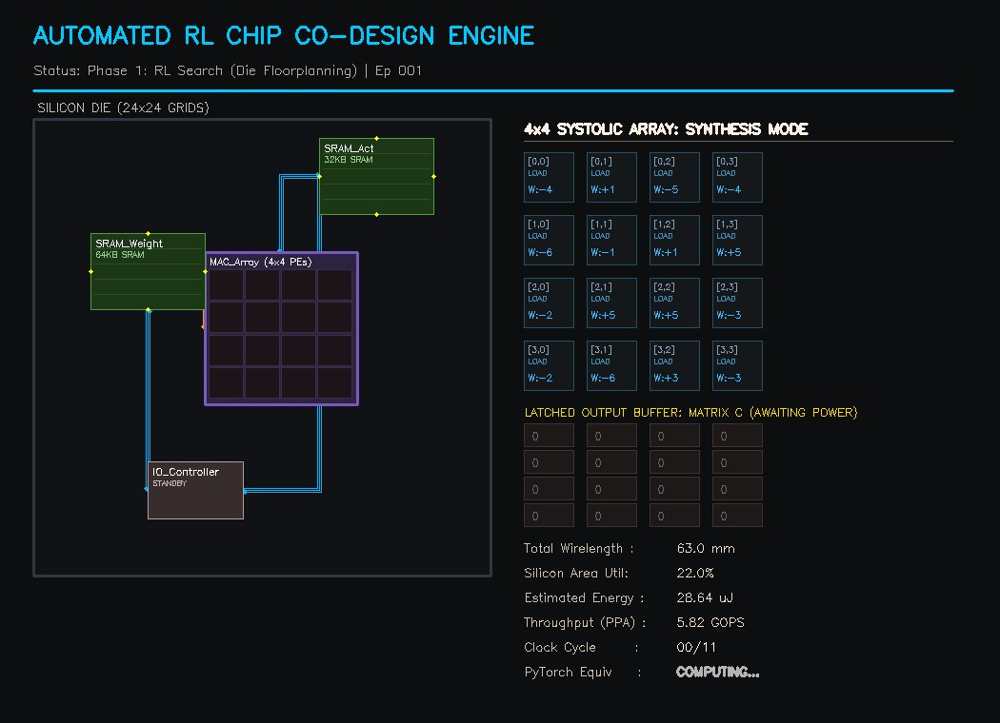


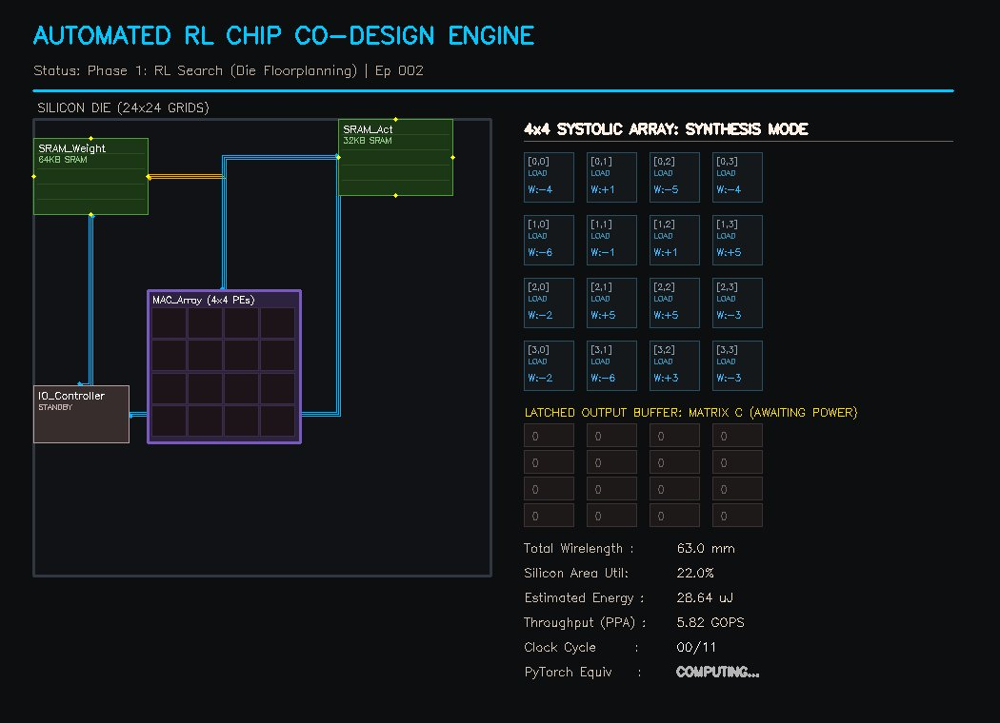


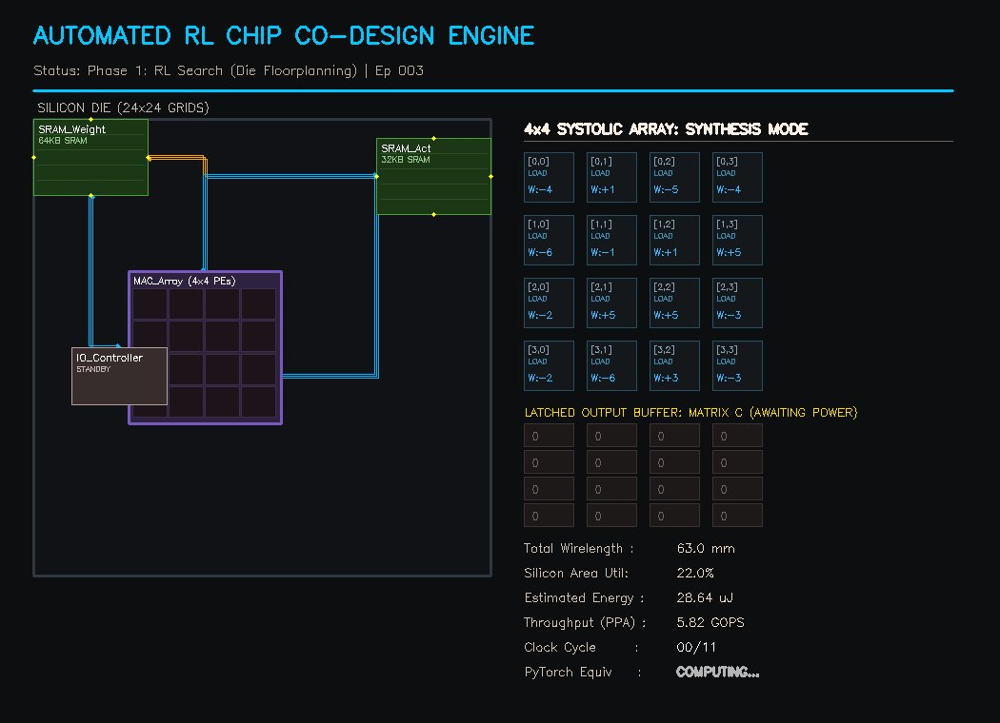


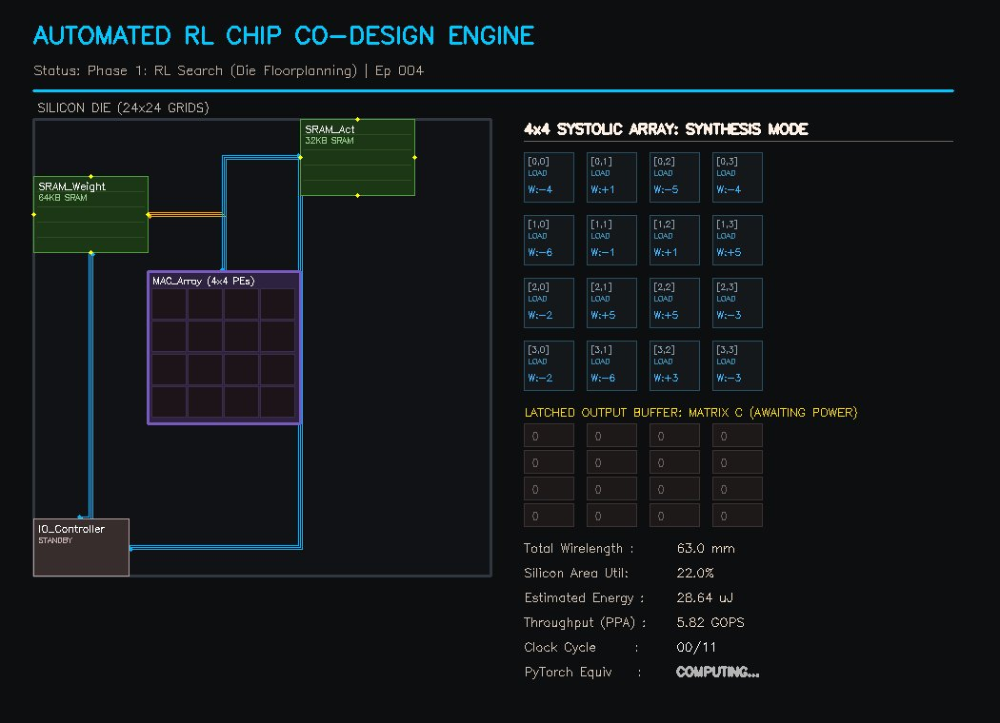


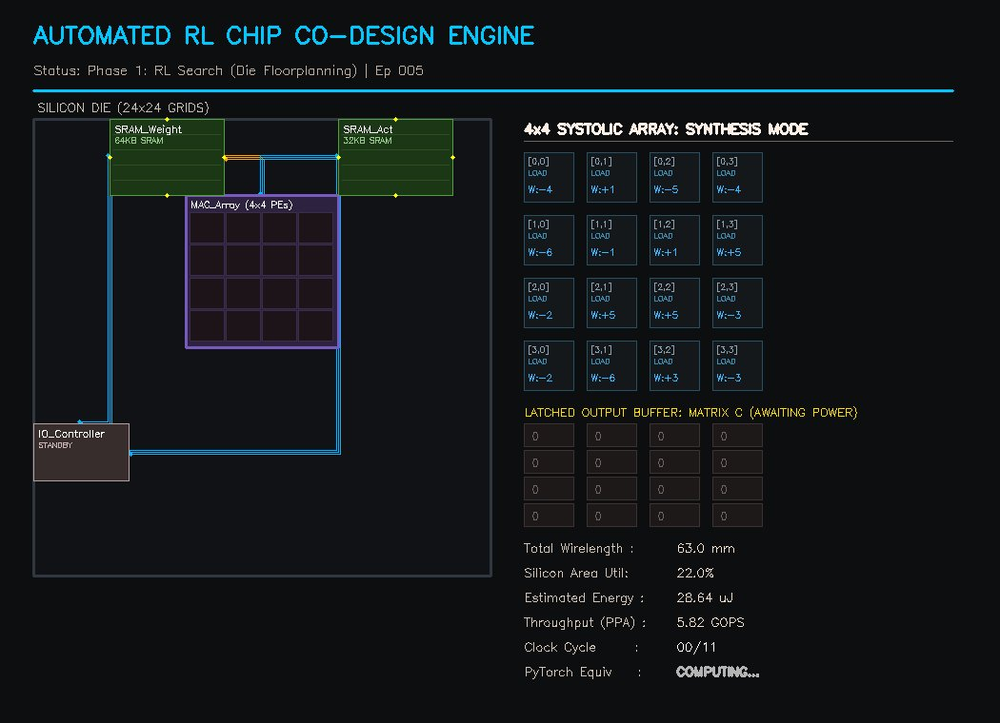


...


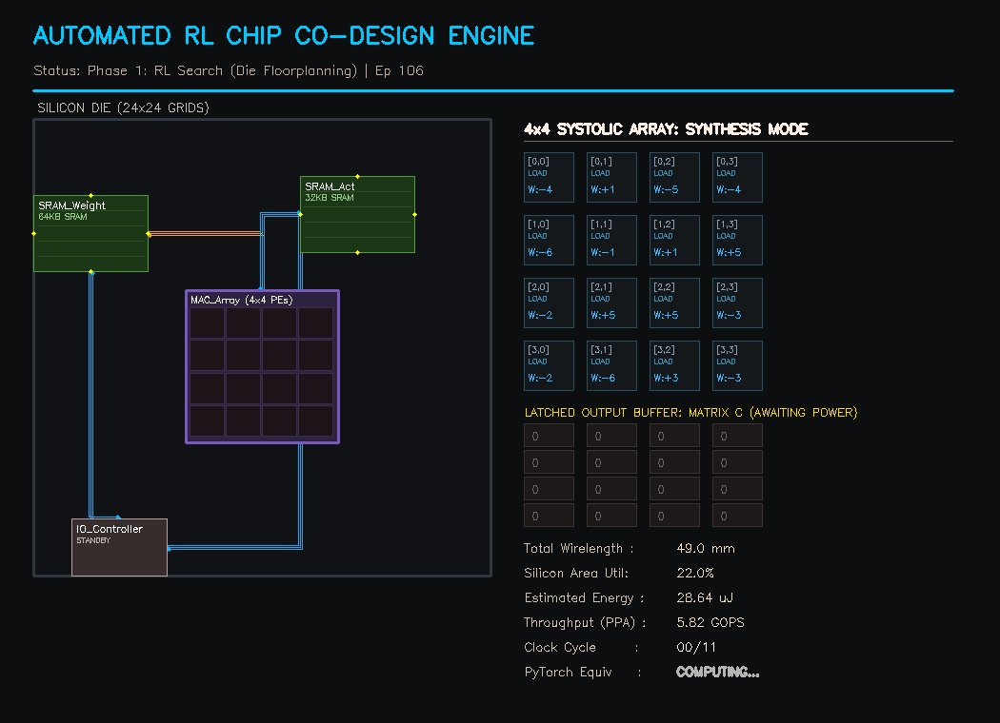


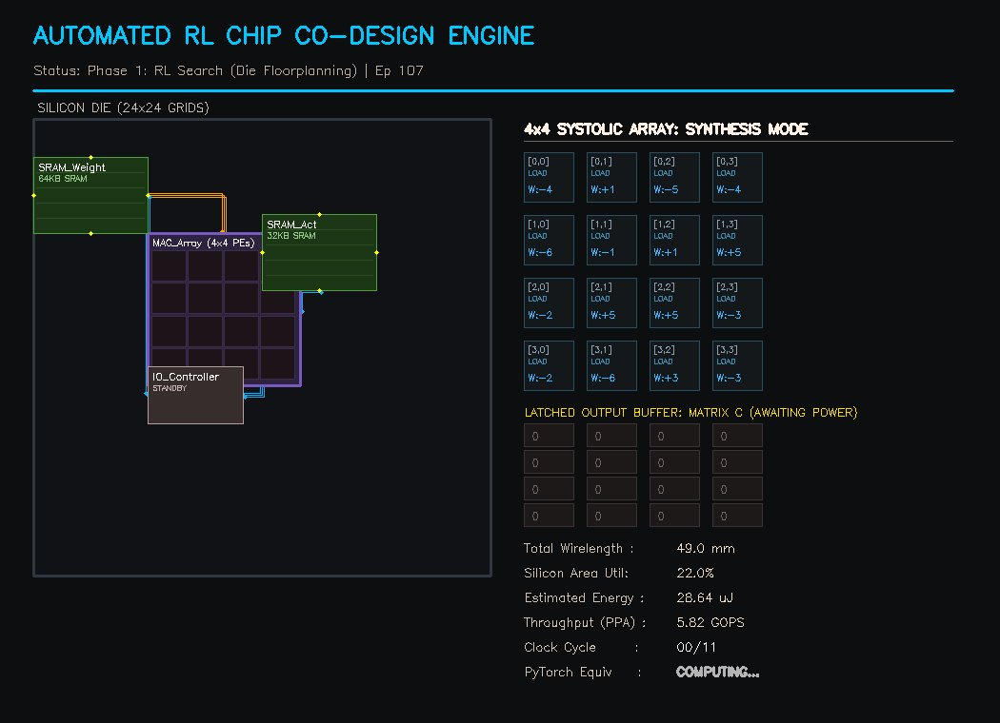


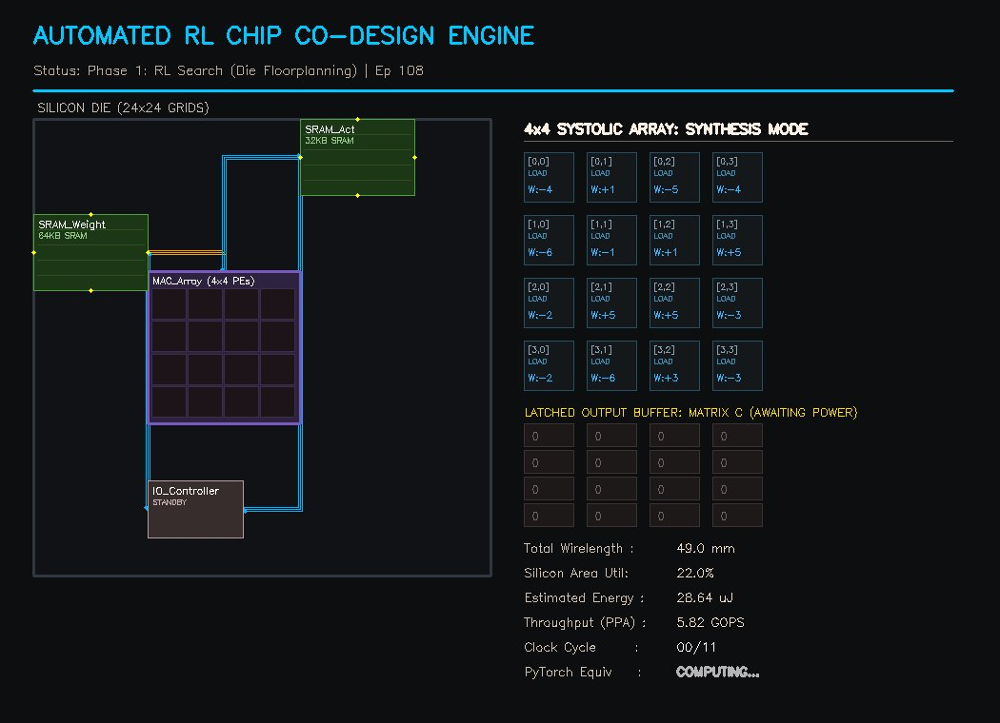


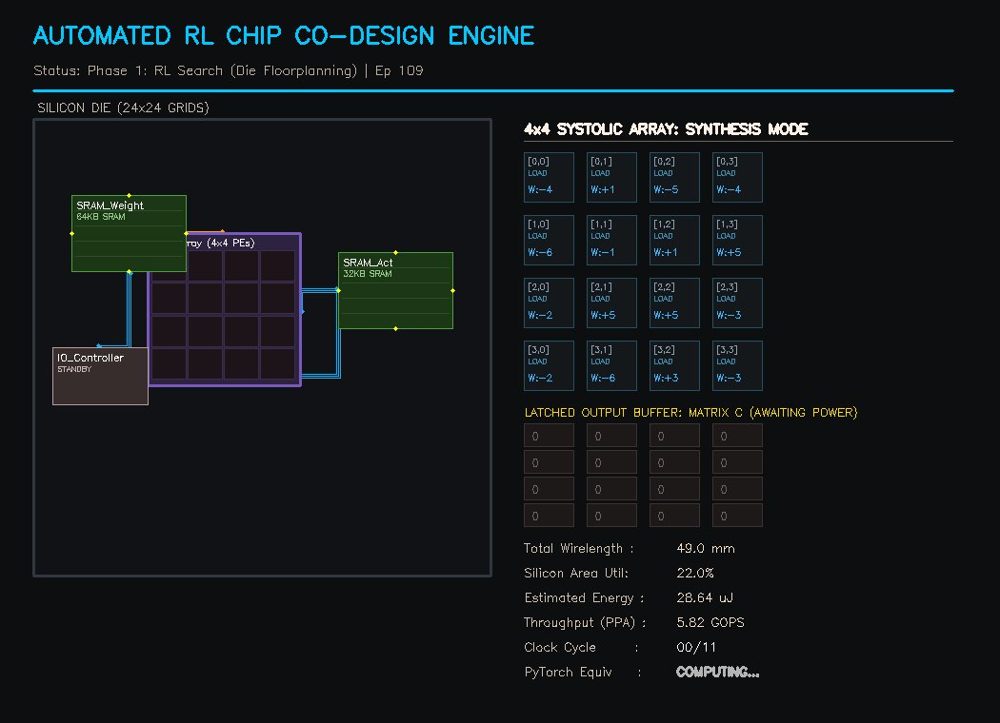


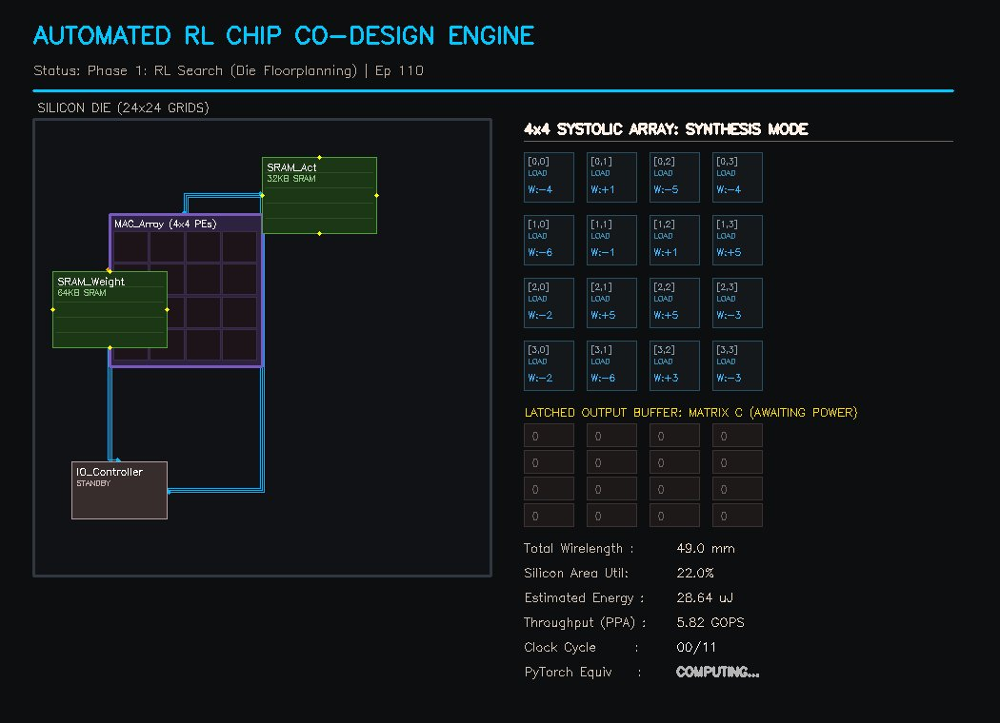

Synthesized Silicon Layout Locked. Initializing Systolic Clock Rails & SRAM Buffers...



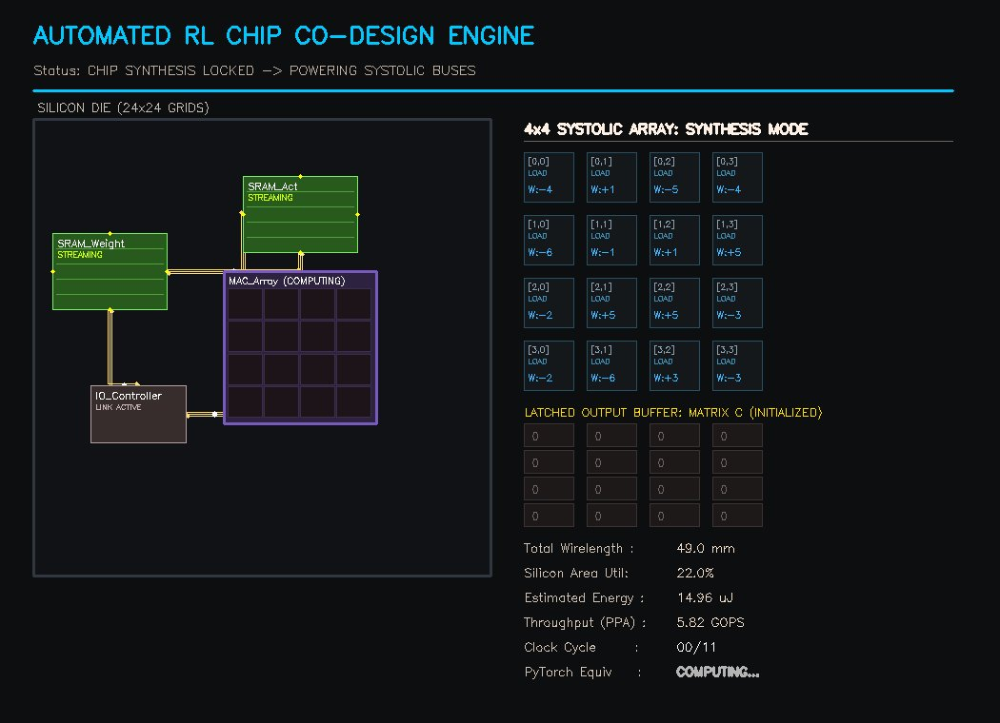


Phase 2: Streaming 3 Unseen Batches into Hardware...



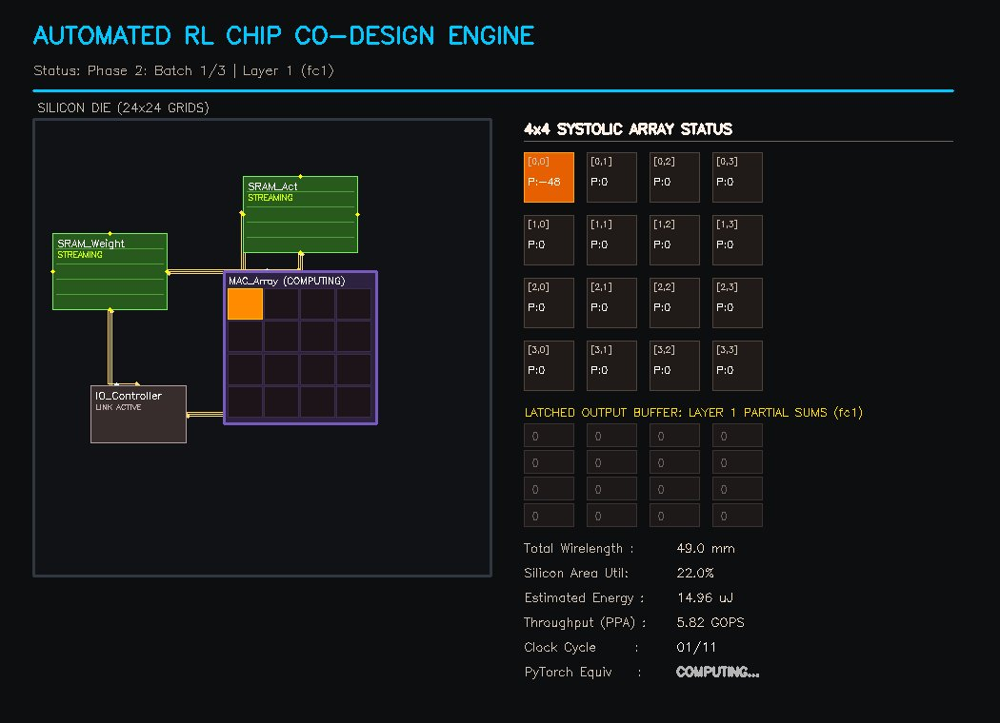


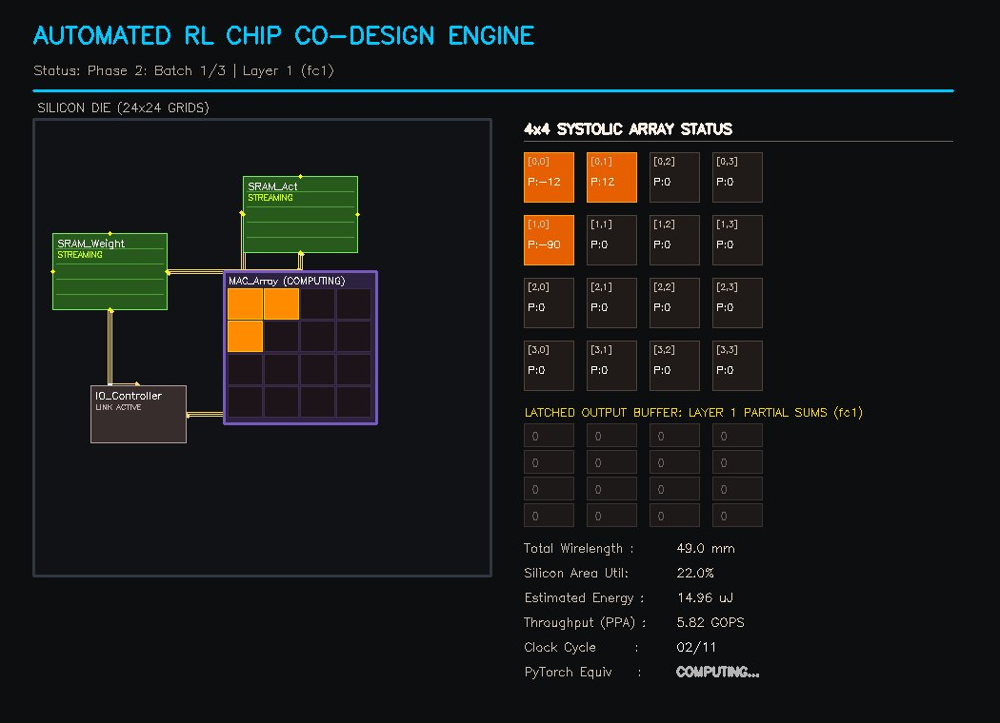


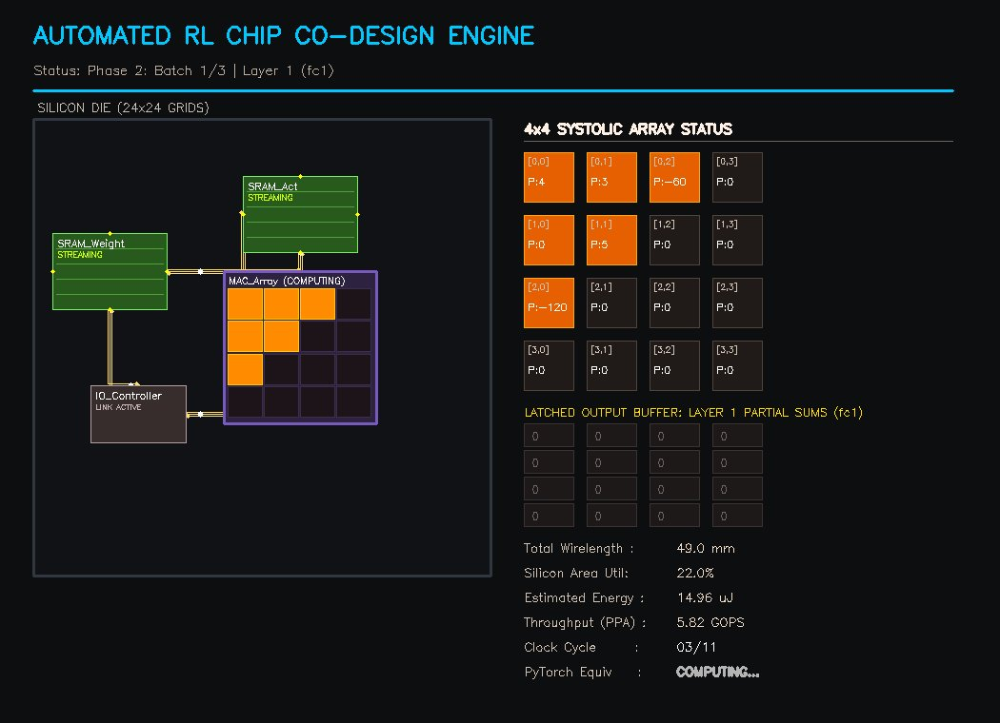


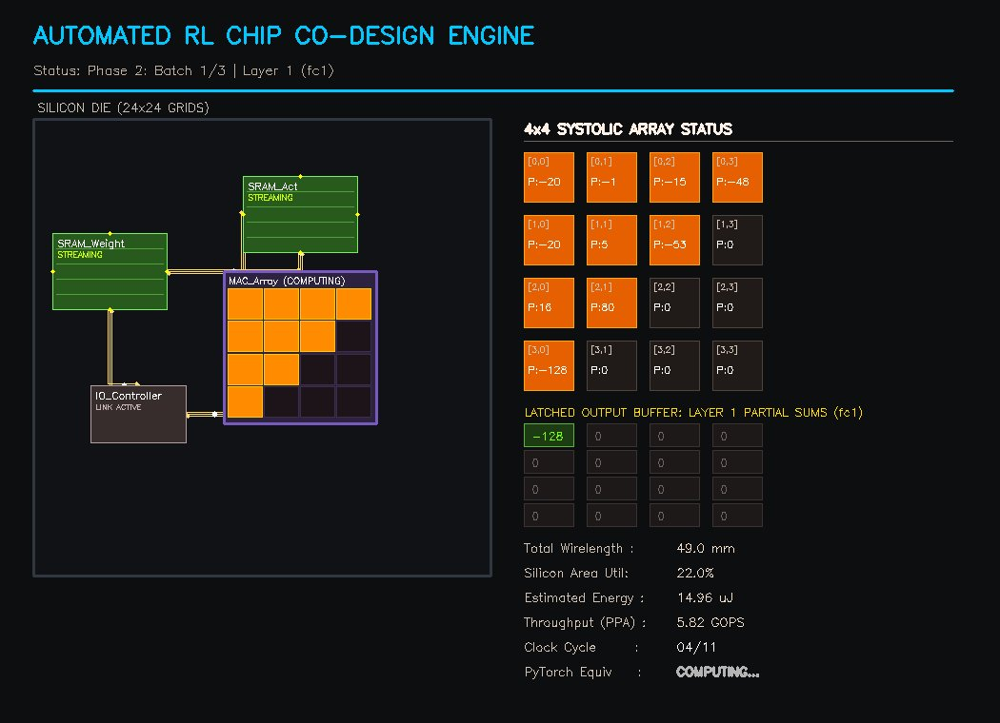


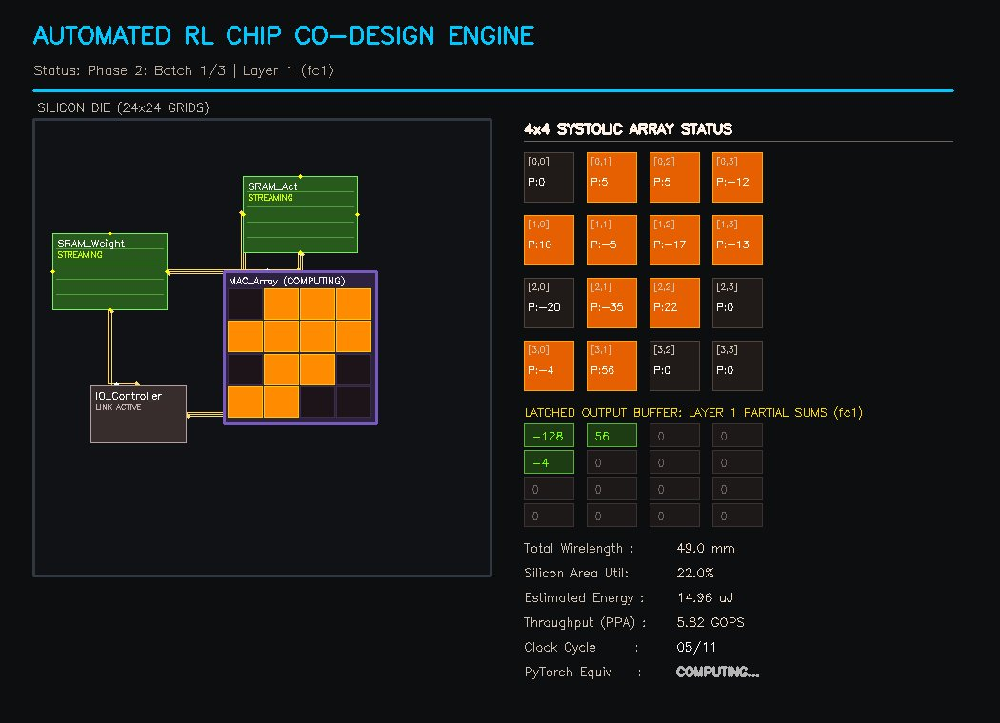


...


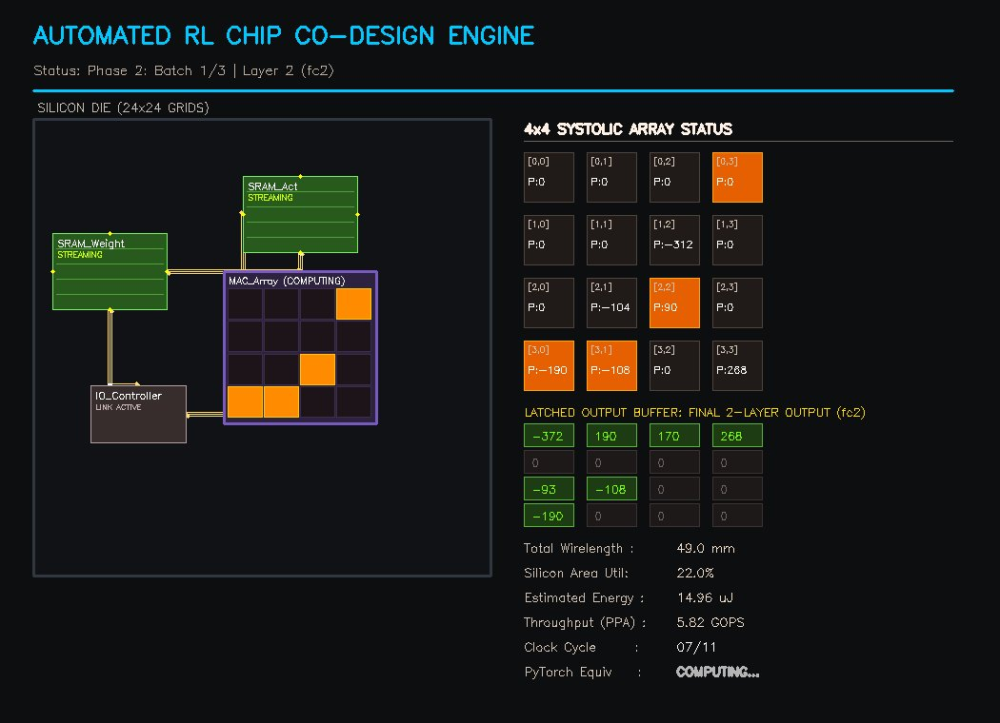


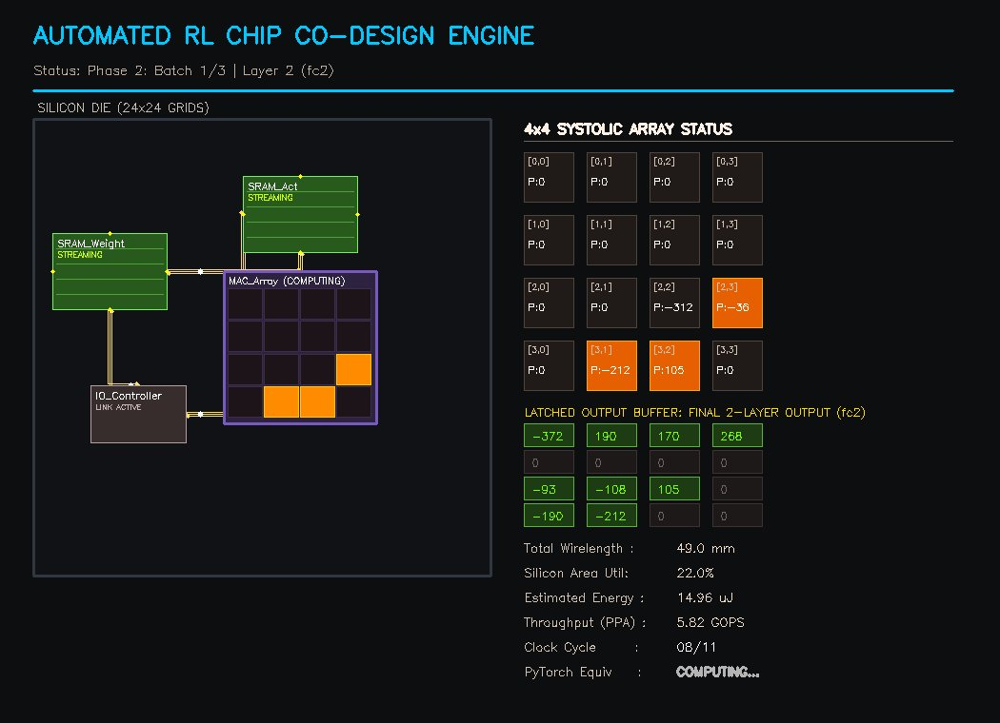


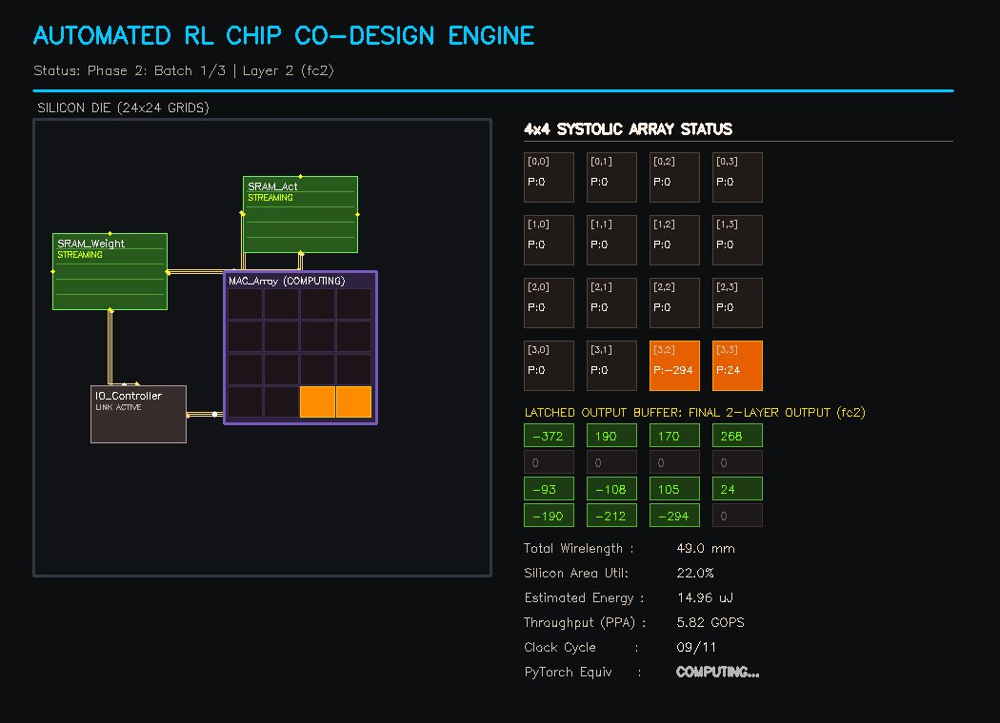


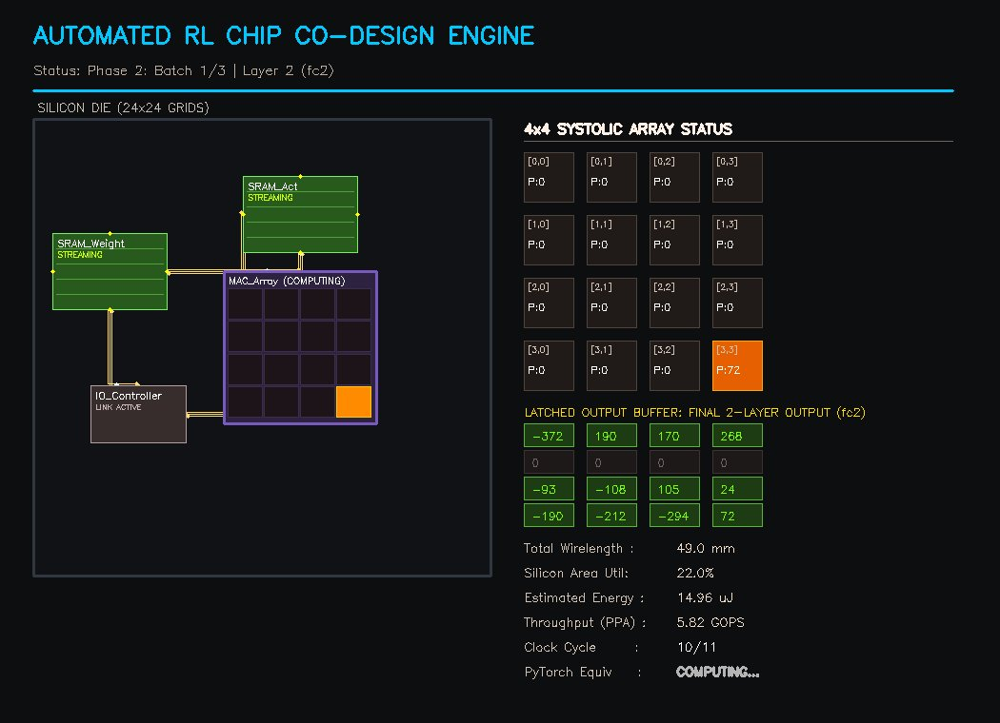


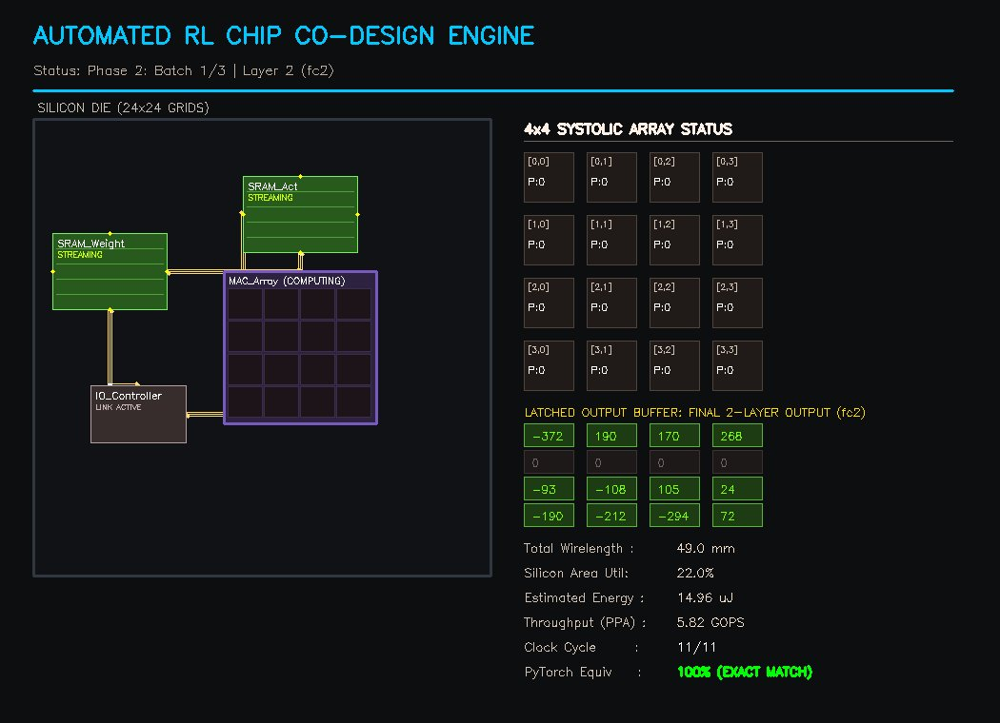

  -> Unseen Batch 1/3: Verified 2-Layer Equivalence = True



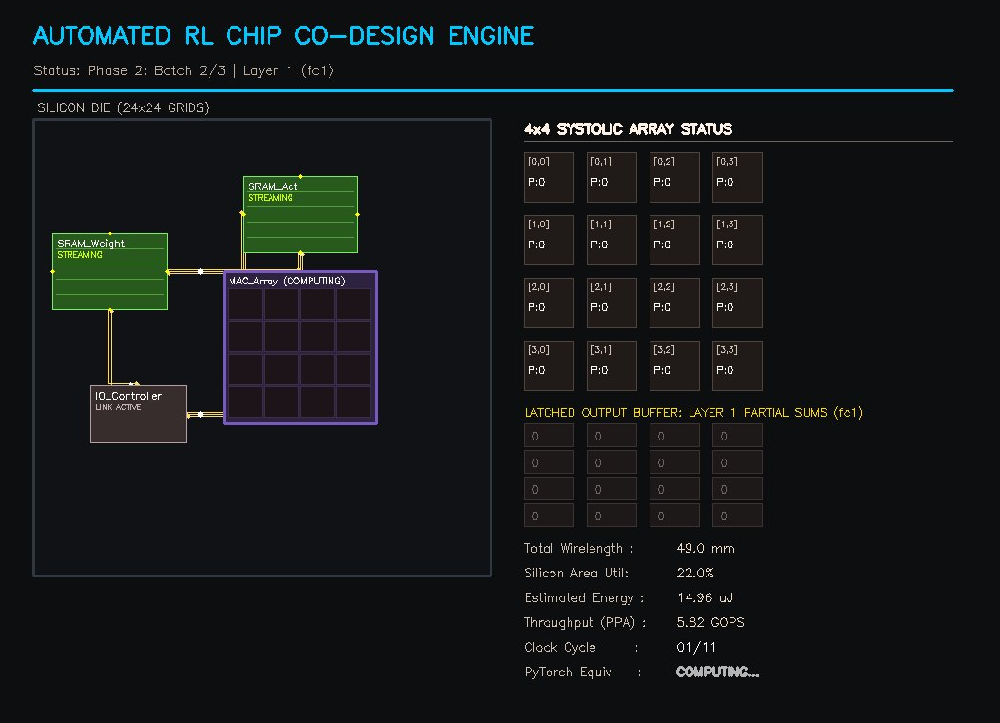


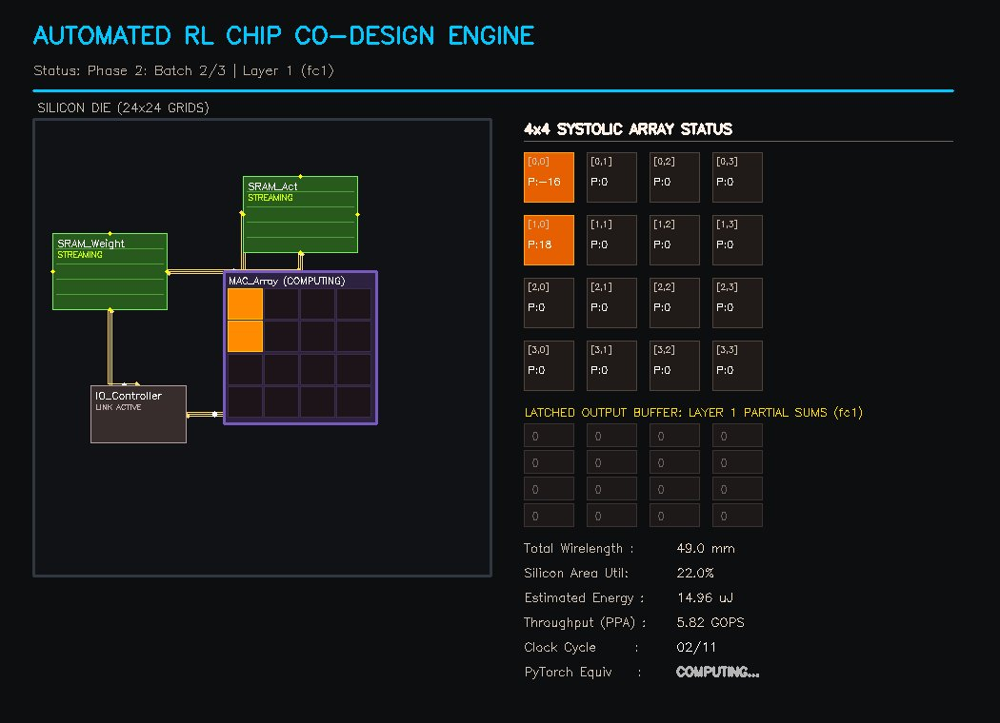


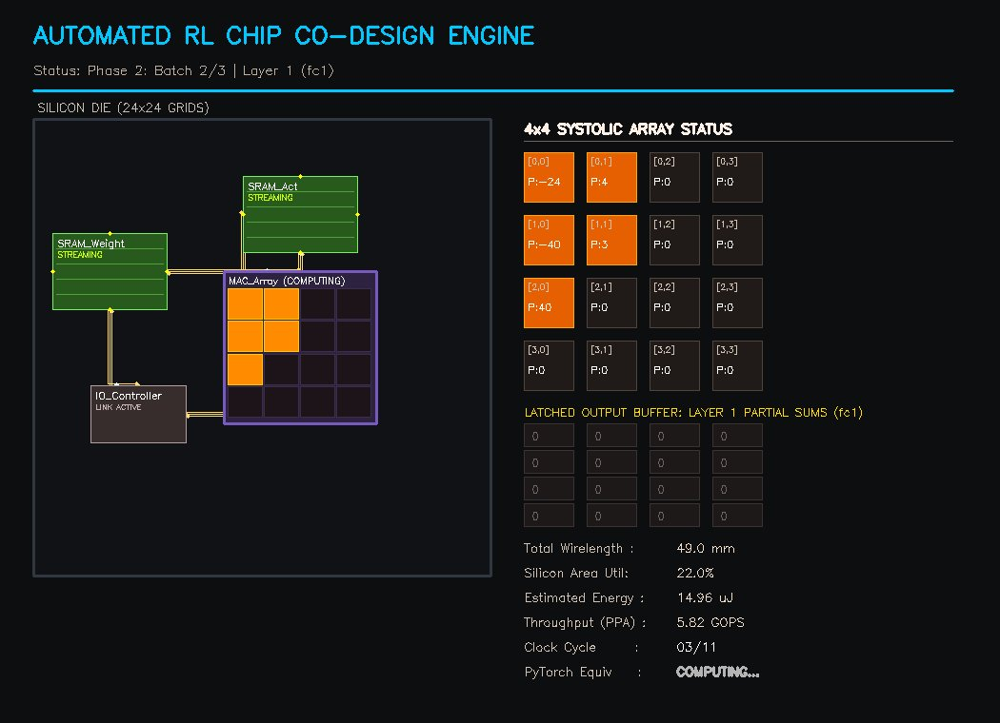


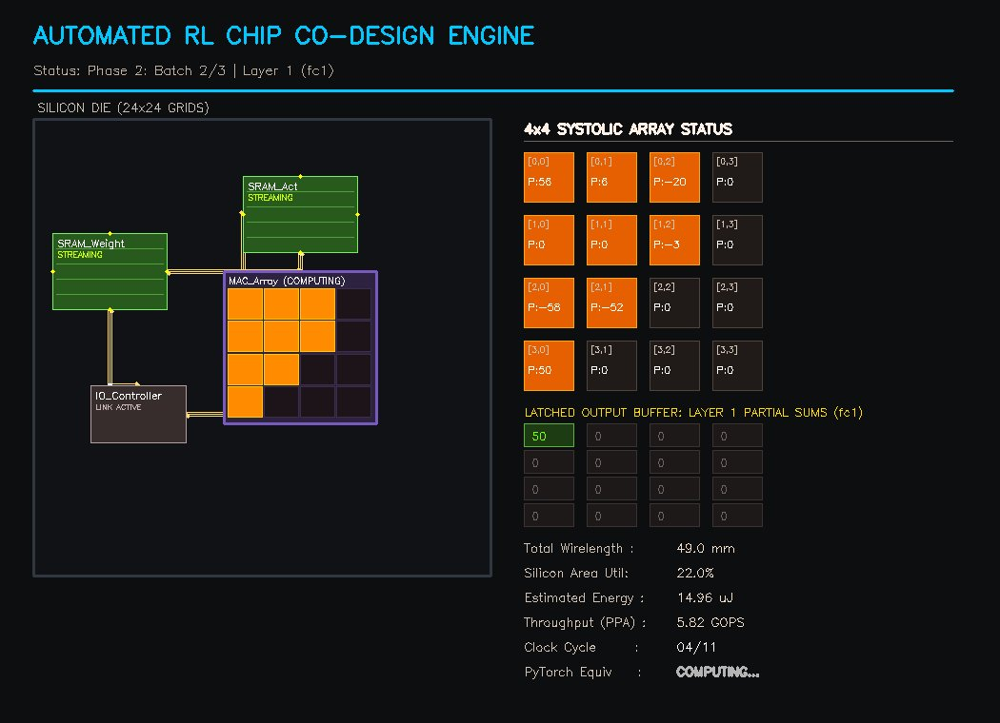


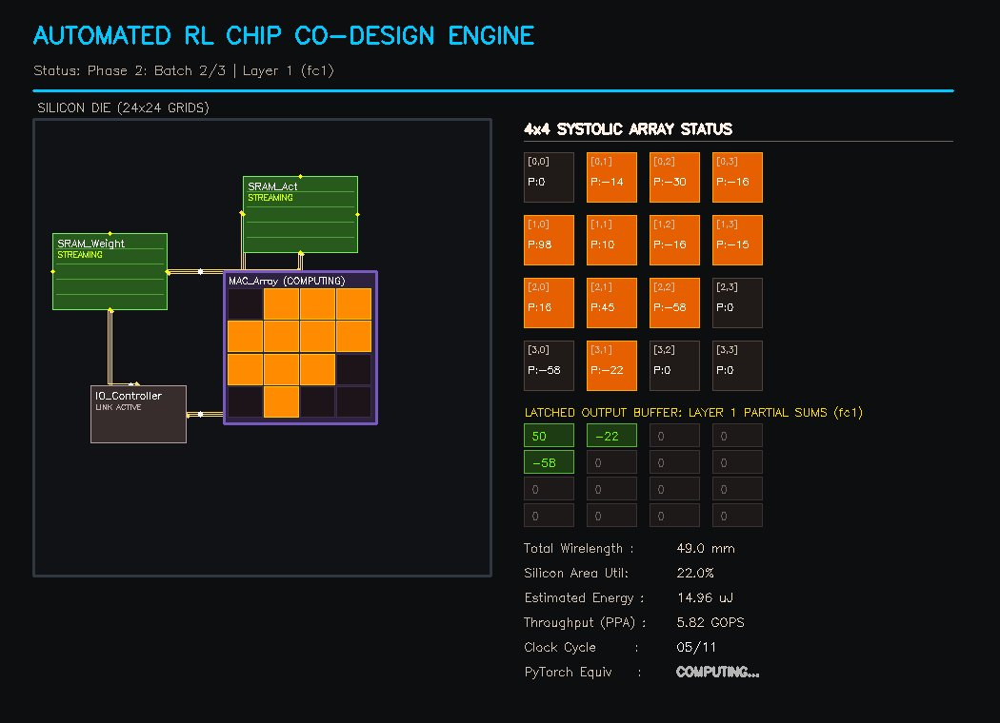


...


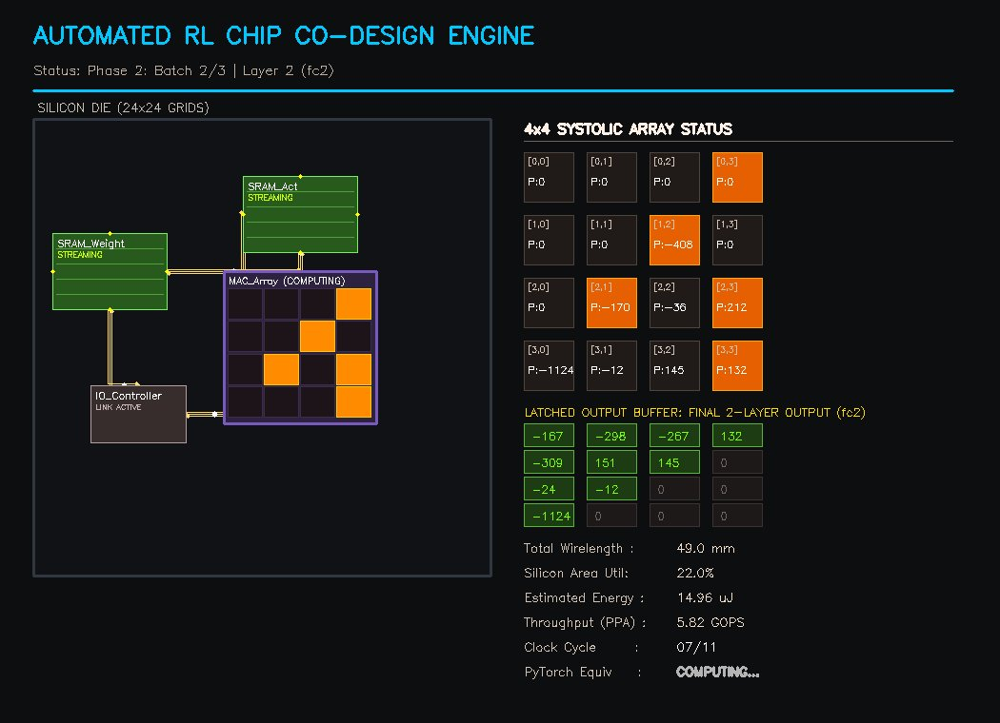


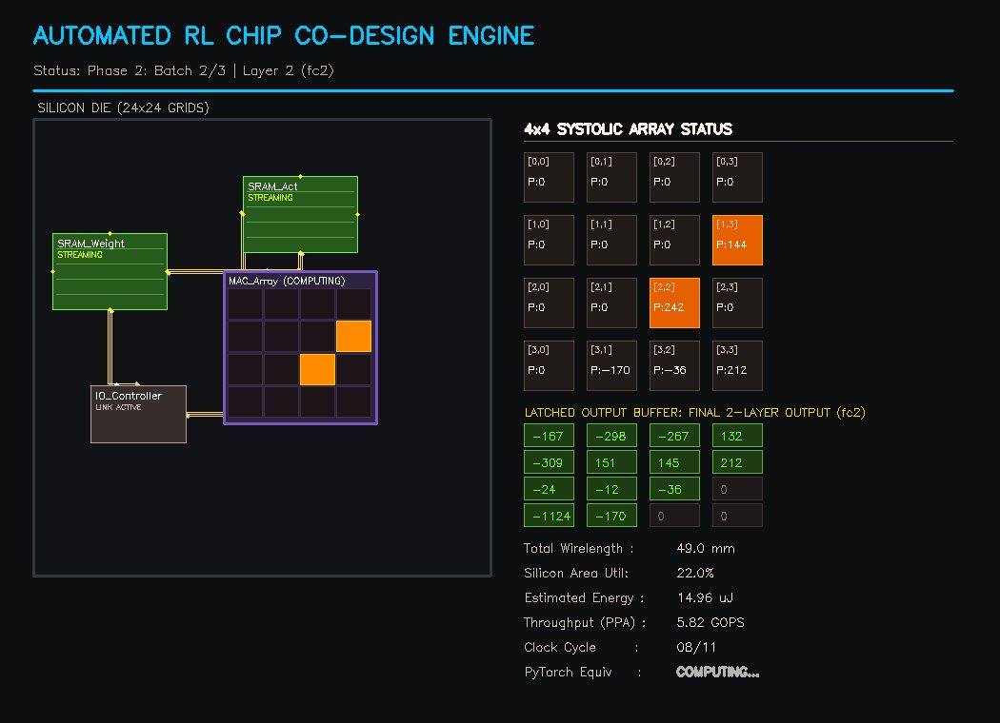


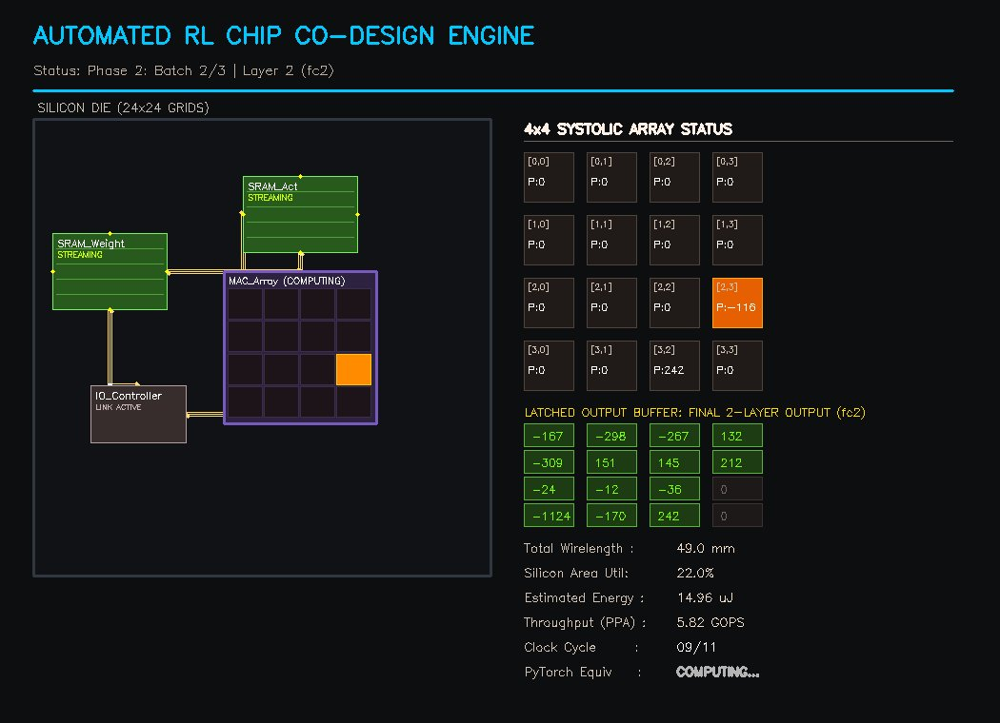


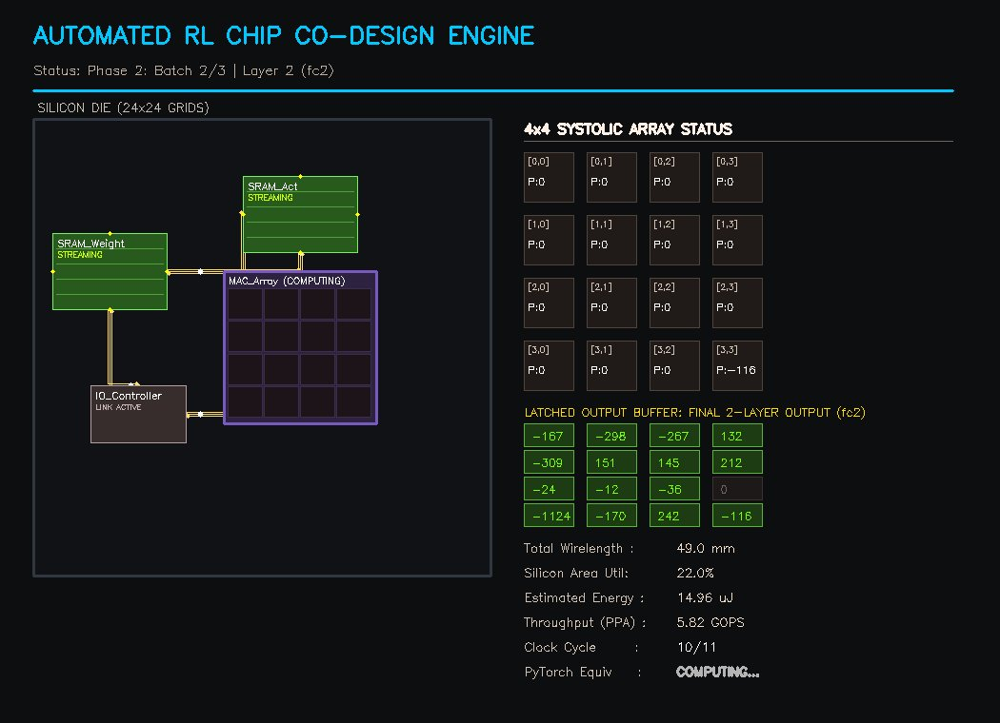


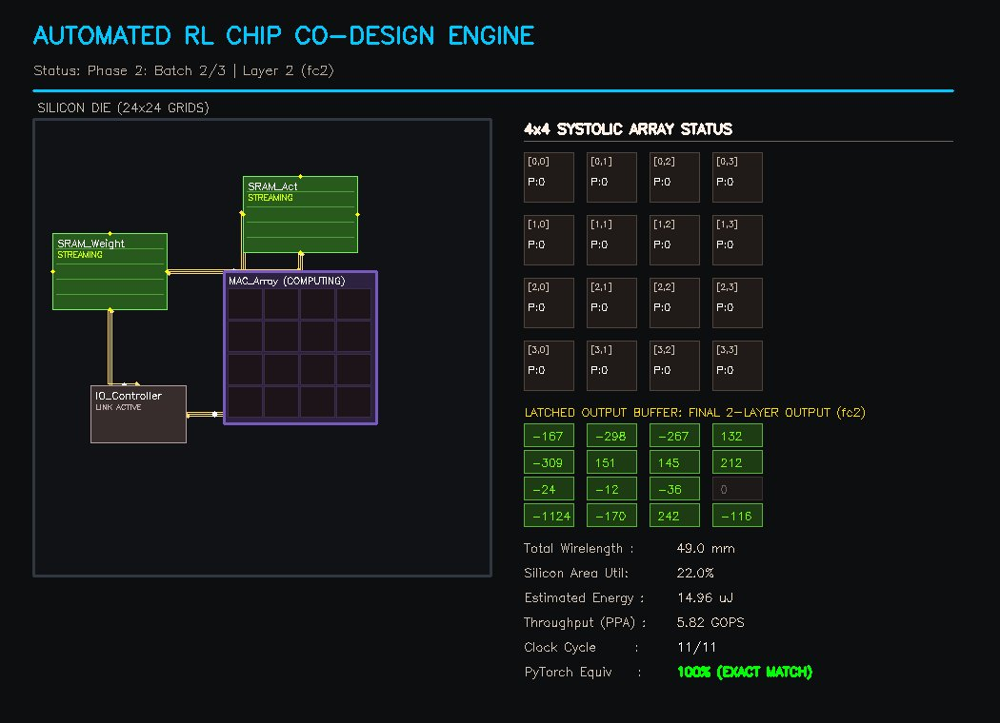

  -> Unseen Batch 2/3: Verified 2-Layer Equivalence = True



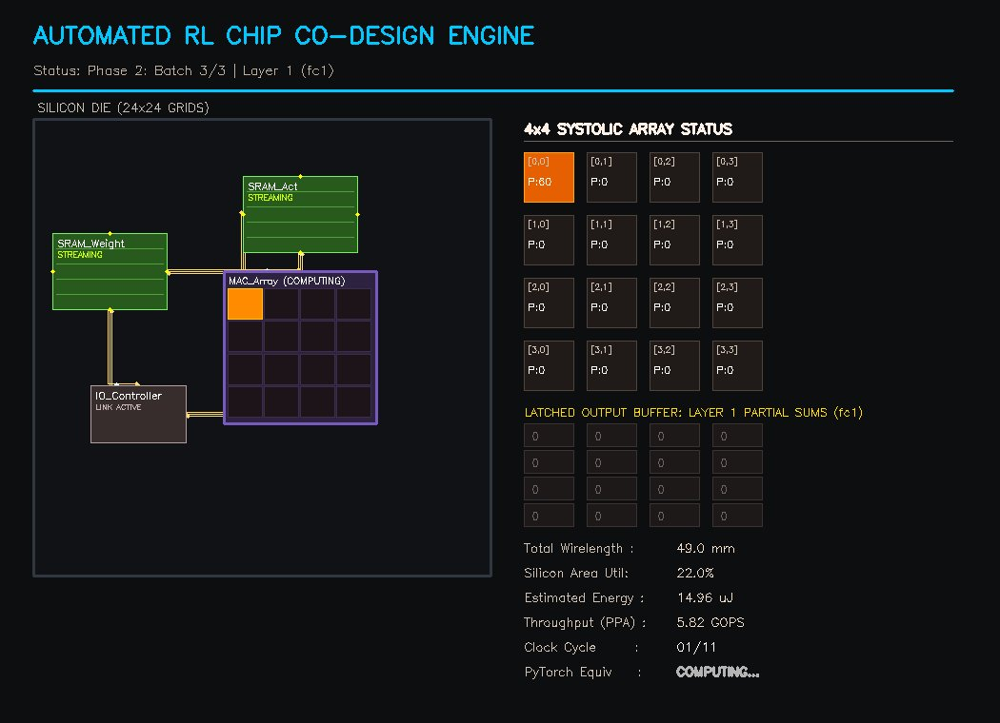


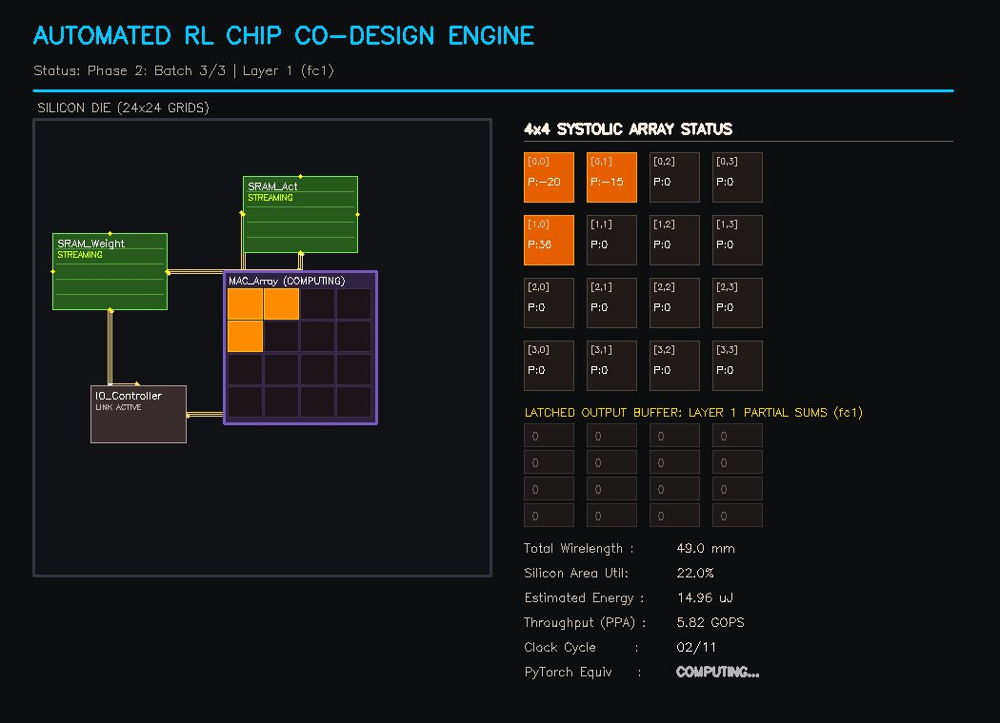


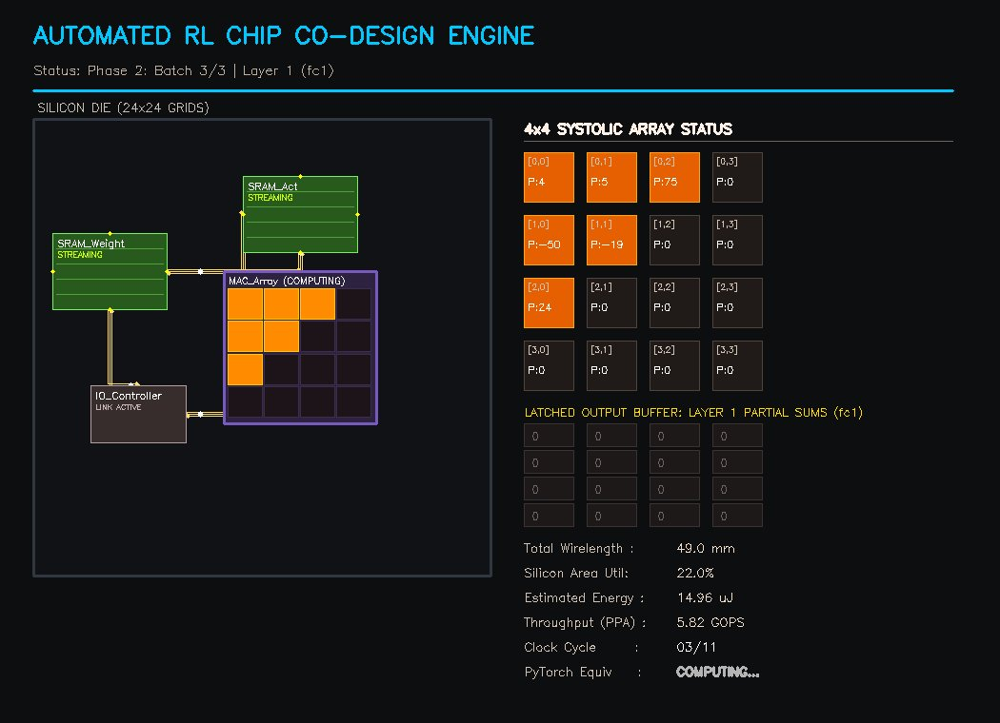


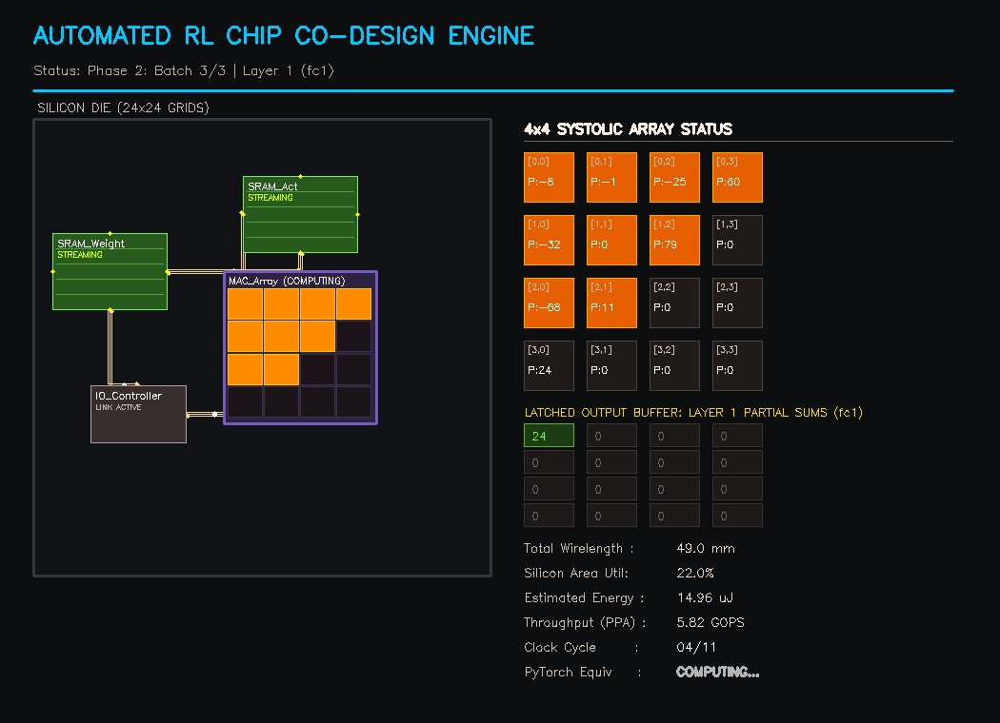


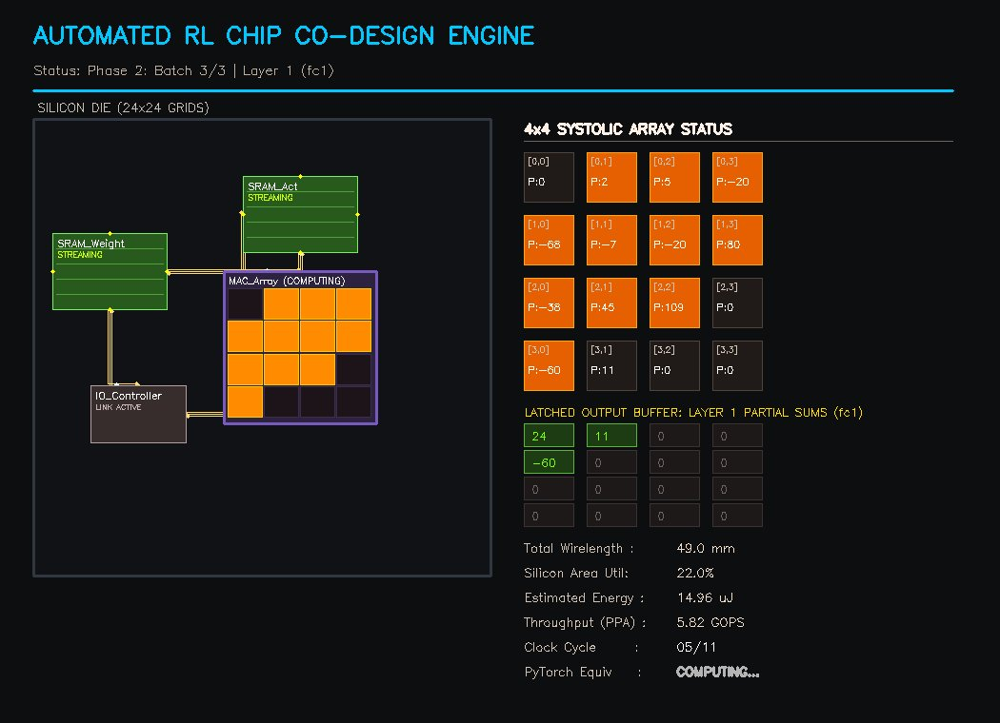


...


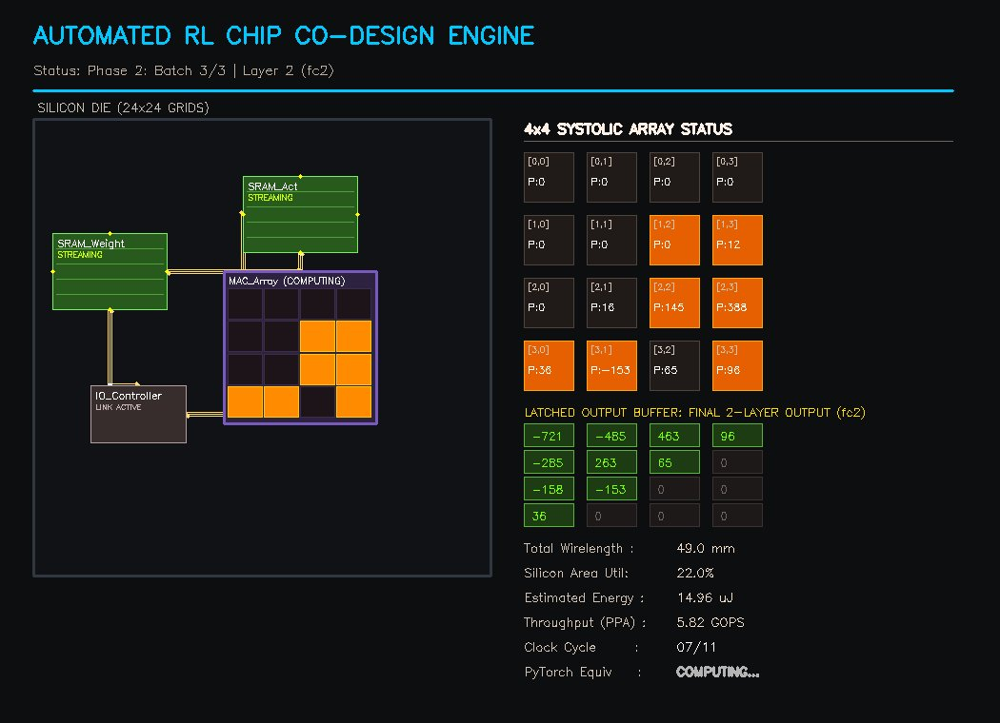


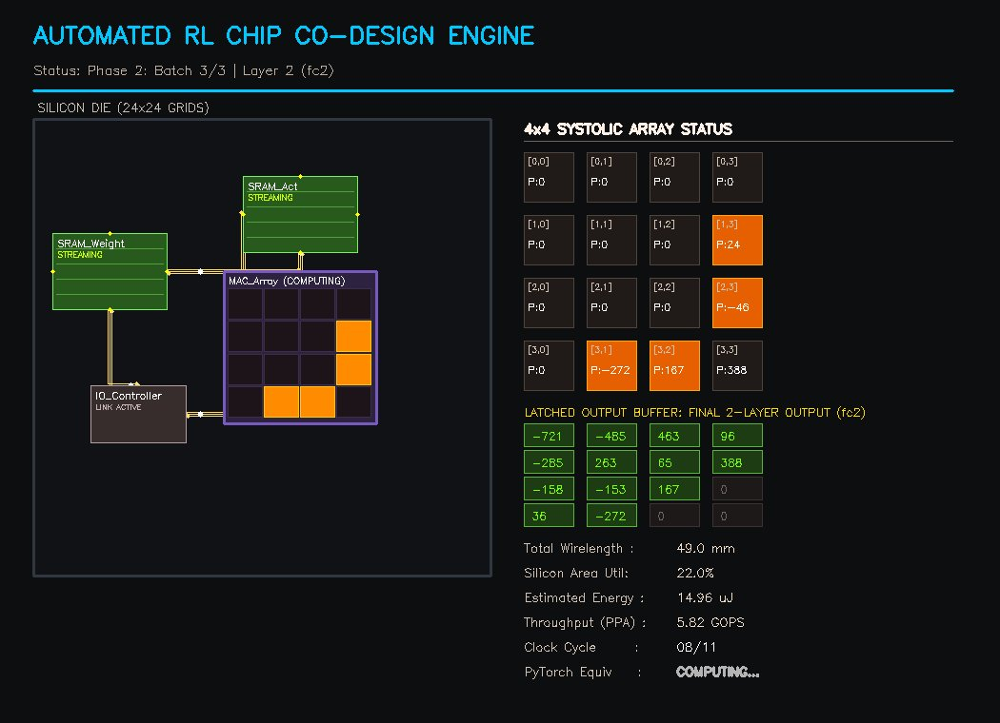


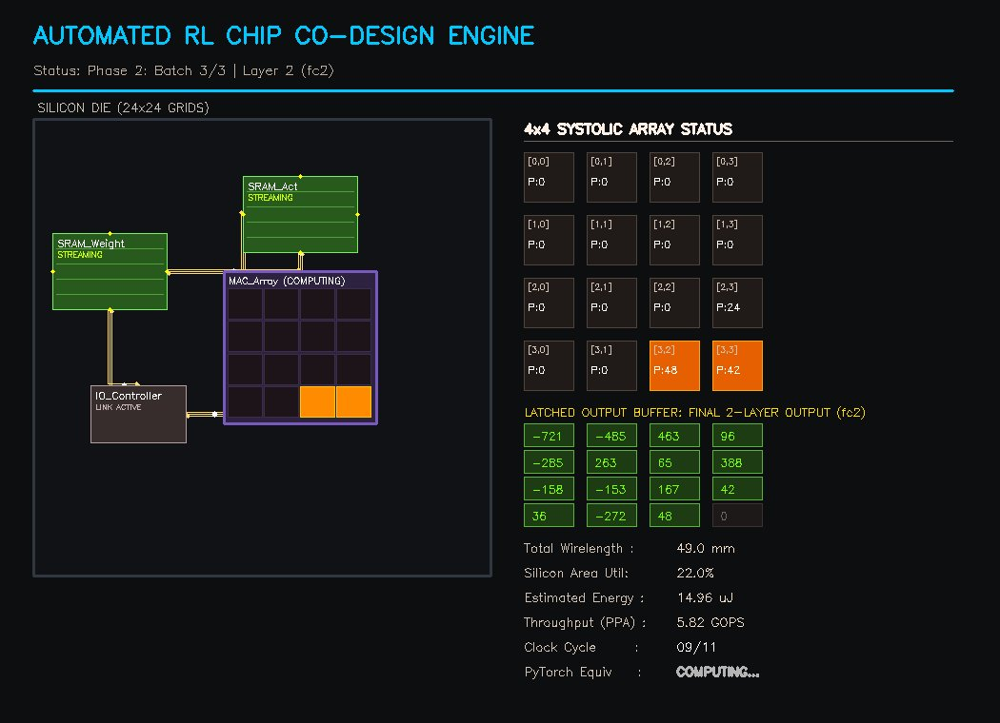


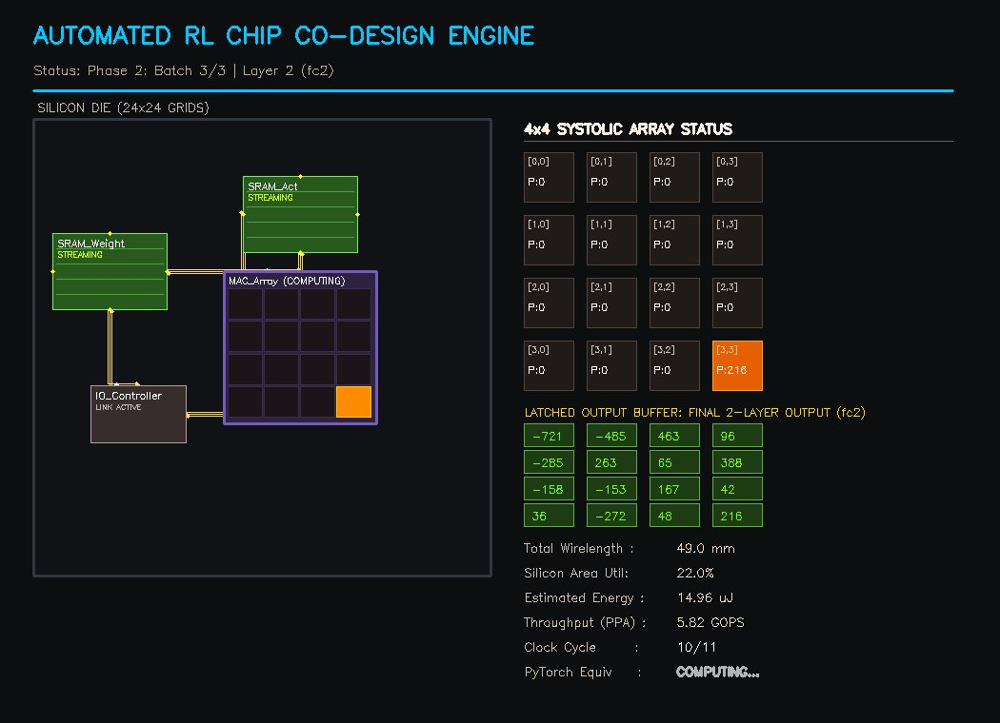


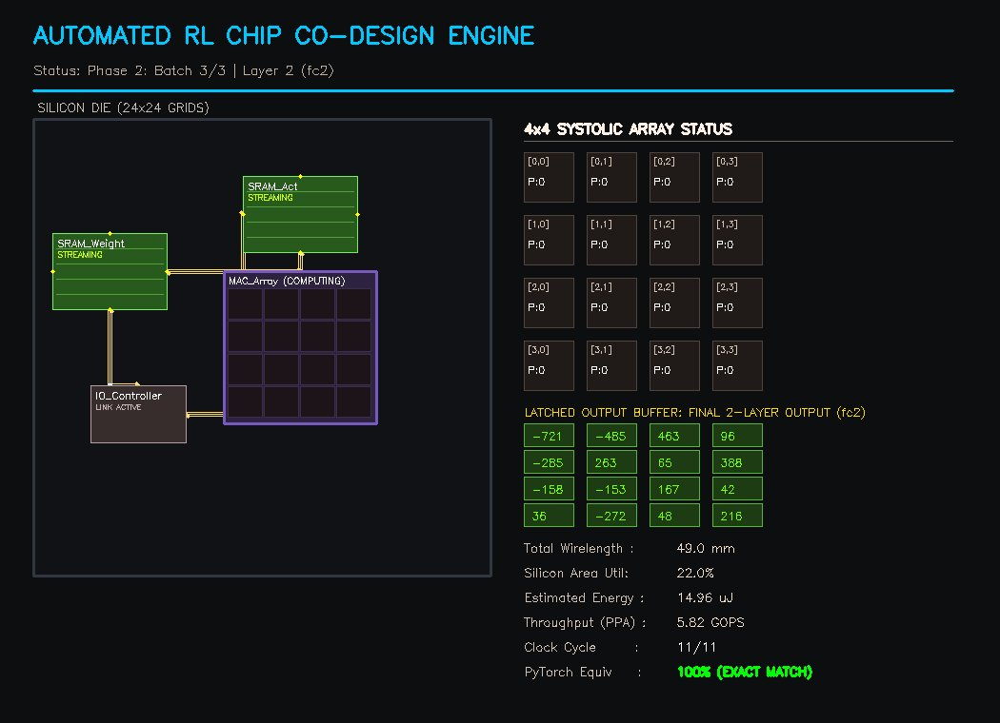

  -> Unseen Batch 3/3: Verified 2-Layer Equivalence = True

Holding final verified showcase...

Encoding 288 frames into native H.264 MP4 'chip_codesign_timelapse.mp4'...
Success: Video saved with duration: 24.0s



AUTOMATED RL CHIP CO-DESIGN BENCHMARK & PPA REPORT
Floorplan Area Utilization   : 22.0% of Silicon Die
Baseline Unoptimized Wire    : 106.00 mm
RL Optimized Wire Length     : 49.00 mm
Interconnect Wire Reduction  : 53.8% FASTER ROUTING
Estimated Energy Per Layer   : 14.96 uJ
Compute Throughput (500MHz)  : 5.82 GOPS
Video Recording Duration     : 24.0 seconds (288 frames)
Downloadable Playable Video  : 'chip_codesign_timelapse.mp4'


In [6]:
import os
import cv2
import numpy as np
import time
import json
import base64
import torch
import torch.nn as nn
import imageio
from IPython.display import display, HTML

# ==============================================================================
# 1. DEEP LEARNING WORKLOAD (PyTorch 2-Layer Model)
# ==============================================================================
class TwoLayerVisionNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(4, 4, bias=False)
        self.fc2 = nn.Linear(4, 4, bias=False)
        nn.init.orthogonal_(self.fc1.weight)
        nn.init.orthogonal_(self.fc2.weight)

    def forward(self, x):
        return self.fc2(torch.relu(self.fc1(x)))

class WorkloadExtractor:
    def __init__(self, seed=42):
        torch.manual_seed(seed)
        np.random.seed(seed)
        self.model = TwoLayerVisionNet()
        self.model.eval()

    def get_quantized_network(self):
        with torch.no_grad():
            W1 = self.model.fc1.weight.detach().numpy()
            W2 = self.model.fc2.weight.detach().numpy()

        W1_int = np.clip(np.round(W1 * 8), -15, 15).astype(int)
        W2_int = np.clip(np.round(W2 * 8), -15, 15).astype(int)
        return W1_int.T, W2_int.T

    def generate_unseen_batch(self):
        x_raw = torch.randn(4, 4)
        x_int = np.clip(np.round(x_raw.numpy() * 8), -15, 15).astype(int)
        W1_t, W2_t = self.get_quantized_network()

        act1 = np.maximum(0, np.dot(x_int, W1_t))
        golden_final = np.dot(act1, W2_t)
        return x_int, golden_final


# ==============================================================================
# 2. CYCLE-ACCURATE SYSTOLIC HARDWARE CORE
# ==============================================================================
class SystolicPE:
    def __init__(self, weight=0):
        self.weight = int(weight)
        self.act_reg = 0
        self.psum_reg = 0
        self.is_active = False

class SystolicArrayCore:
    def __init__(self, weights_4x4):
        self.load_weights(weights_4x4)
        self.T_STEPS = 11

    def load_weights(self, weights_4x4):
        self.W = weights_4x4
        self.grid = [[SystolicPE(weights_4x4[r, c]) for c in range(4)] for r in range(4)]
        self.latched_output_C = np.zeros((4, 4), dtype=int)

    def prepare_skewed_inputs(self, A_matrix):
        skewed = np.zeros((4, self.T_STEPS), dtype=int)
        for k in range(4):
            skewed[k, k:k+4] = A_matrix[:, k]
        return skewed

    def run_cycle(self, t, skewed_inputs):
        left_inputs = skewed_inputs[:, t]
        next_act = np.zeros((4, 4), dtype=int)
        next_psum = np.zeros((4, 4), dtype=int)
        active_count = 0

        for r in range(4):
            for c in range(4):
                in_act = left_inputs[r] if c == 0 else self.grid[r][c-1].act_reg
                in_psum = 0 if r == 0 else self.grid[r-1][c].psum_reg

                next_act[r, c] = in_act
                next_psum[r, c] = in_psum + (in_act * self.W[r, c])
                if in_act != 0:
                    active_count += 1

        active_mask = np.zeros((4, 4), dtype=bool)
        for r in range(4):
            for c in range(4):
                self.grid[r][c].act_reg = next_act[r, c]
                self.grid[r][c].psum_reg = next_psum[r, c]
                active_mask[r, c] = (next_act[r, c] != 0)

        for j in range(4):
            for i in range(4):
                if t == (i + j + 3):
                    self.latched_output_C[i, j] = self.grid[3][j].psum_reg

        p_matrix = np.array([[self.grid[r][c].psum_reg for c in range(4)] for r in range(4)])
        return left_inputs, p_matrix, active_mask, active_count, self.latched_output_C


# ==============================================================================
# 3. SILICON DIE FLOORPLANNER & HARDWARE PRIMITIVES
# ==============================================================================
class HardwareComponent:
    def __init__(self, name, comp_type, w, h):
        self.name = name
        self.comp_type = comp_type
        self.w, self.h = w, h
        self.x, self.y = 0, 0
        self.is_powered = False

    @property
    def area(self):
        return self.w * self.h

    @property
    def center(self):
        return (self.x + self.w / 2.0, self.y + self.h / 2.0)

    @property
    def ports(self):
        return {
            "N": (self.x + self.w / 2.0, self.y),
            "S": (self.x + self.w / 2.0, self.y + self.h),
            "W": (self.x, self.y + self.h / 2.0),
            "E": (self.x + self.w, self.y + self.h / 2.0)
        }

    def render(self, canvas, scale, origin):
        raise NotImplementedError

class SRAMBuffer(HardwareComponent):
    def __init__(self, name, w, h, capacity_kb=64):
        super().__init__(name, "SRAM", w, h)
        self.capacity_kb = capacity_kb

    def render(self, canvas, scale, origin):
        ox, oy = origin
        px1, py1 = int(ox + self.x * scale), int(oy + self.y * scale)
        px2, py2 = int(px1 + self.w * scale), int(py1 + self.h * scale)

        # Base block style
        bg_col = (30, 90, 40) if self.is_powered else (22, 55, 28)
        border_col = (100, 240, 120) if self.is_powered else (60, 160, 80)
        cv2.rectangle(canvas, (px1, py1), (px2, py2), bg_col, -1)
        cv2.rectangle(canvas, (px1, py1), (px2, py2), border_col, 1)

        # Internal memory wordlines
        step_y = (py2 - py1) / 5
        for i in range(1, 5):
            wy = int(py1 + i * step_y)
            line_col = (60, 160, 80) if self.is_powered else (35, 80, 45)
            cv2.line(canvas, (px1 + 4, wy), (px2 - 4, wy), line_col, 1)

        for pt in self.ports.values():
            cv2.circle(canvas, (int(ox + pt[0] * scale), int(oy + pt[1] * scale)), 2, (0, 255, 255), -1)

        cv2.putText(canvas, self.name, (px1 + 5, py1 + 14), cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)
        sub_text = "STREAMING" if self.is_powered else f"{self.capacity_kb}KB SRAM"
        sub_col = (0, 255, 200) if self.is_powered else (140, 200, 150)
        cv2.putText(canvas, sub_text, (px1 + 5, py1 + 25), cv2.FONT_HERSHEY_SIMPLEX, 0.28, sub_col, 1)

class SystolicComputeCore(HardwareComponent):
    def __init__(self, name, rows=4, cols=4, w=8, h=8):
        super().__init__(name, "COMPUTE_CORE", w, h)
        self.rows, self.cols = rows, cols
        self.pe_active_mask = np.zeros((rows, cols), dtype=bool)

    def render(self, canvas, scale, origin):
        ox, oy = origin
        px1, py1 = int(ox + self.x * scale), int(oy + self.y * scale)
        px2, py2 = int(px1 + self.w * scale), int(py1 + self.h * scale)

        cv2.rectangle(canvas, (px1, py1), (px2, py2), (65, 35, 45), -1)
        cv2.rectangle(canvas, (px1, py1), (px2, py2), (190, 90, 120), 2)

        cw = (px2 - px1 - 8) / self.cols
        ch = (py2 - py1 - 22) / self.rows
        for r in range(self.rows):
            for c in range(self.cols):
                cx1, cy1 = int(px1 + 4 + c * cw), int(py1 + 18 + r * ch)
                cx2, cy2 = int(cx1 + cw - 2), int(cy1 + ch - 2)
                is_act = self.pe_active_mask[r, c]
                cv2.rectangle(canvas, (cx1, cy1), (cx2, cy2), (0, 140, 255) if is_act else (25, 20, 28), -1)
                cv2.rectangle(canvas, (cx1, cy1), (cx2, cy2), (0, 200, 255) if is_act else (75, 45, 60), 1)

        core_status = "(COMPUTING)" if self.is_powered else "(4x4 PEs)"
        cv2.putText(canvas, f"{self.name} {core_status}", (px1 + 5, py1 + 13),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.32, (255, 255, 255), 1)

class IOController(HardwareComponent):
    def __init__(self, name, w=5, h=3):
        super().__init__(name, "IO_CTRL", w, h)

    def render(self, canvas, scale, origin):
        ox, oy = origin
        px1, py1 = int(ox + self.x * scale), int(oy + self.y * scale)
        px2, py2 = int(px1 + self.w * scale), int(py1 + self.h * scale)
        cv2.rectangle(canvas, (px1, py1), (px2, py2), (45, 45, 55), -1)
        cv2.rectangle(canvas, (px1, py1), (px2, py2), (160, 160, 180), 1)
        cv2.putText(canvas, self.name, (px1 + 5, py1 + 14), cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)
        status_lbl = "LINK ACTIVE" if self.is_powered else "STANDBY"
        cv2.putText(canvas, status_lbl, (px1 + 5, py1 + 25), cv2.FONT_HERSHEY_SIMPLEX, 0.26, (180, 180, 200), 1)

class InterconnectBus:
    def __init__(self, src, dst):
        self.src, self.dst = src, dst
        self.pulse_phase = 0

    def render(self, canvas, scale, origin, is_active=False):
        ox, oy = origin
        min_d = float("inf")
        p1_best, p2_best = None, None

        for p1 in self.src.ports.values():
            for p2 in self.dst.ports.values():
                d = abs(p1[0] - p2[0]) + abs(p1[1] - p2[1])
                if d < min_d:
                    min_d = d
                    p1_best = (int(ox + p1[0] * scale), int(oy + p1[1] * scale))
                    p2_best = (int(ox + p2[0] * scale), int(oy + p2[1] * scale))

        base_color = (0, 165, 255) if "Weight" in self.src.name else (255, 180, 0)
        line_color = (100, 220, 255) if is_active else base_color

        for offset in [-2, 0, 2]:
            op1 = (p1_best[0] + offset, p1_best[1] + offset)
            op2 = (p2_best[0] + offset, p2_best[1] + offset)
            mid = (op2[0], op1[1])
            cv2.line(canvas, op1, mid, line_color, 1)
            cv2.line(canvas, mid, op2, line_color, 1)
            cv2.circle(canvas, op1, 2, line_color, -1)
            cv2.circle(canvas, op2, 2, line_color, -1)

        # Draw a moving signal dot when data is transferring
        if is_active:
            self.pulse_phase = (self.pulse_phase + 1) % 4
            t_ratio = (self.pulse_phase + 1) / 4.0
            mid = (p2_best[0], p1_best[1])
            dot_x = int(p1_best[0] + t_ratio * (mid[0] - p1_best[0]))
            dot_y = int(p1_best[1] + t_ratio * (mid[1] - p1_best[1]))
            cv2.circle(canvas, (dot_x, dot_y), 3, (255, 255, 255), -1)

class SiliconDie:
    def __init__(self, dimension=24):
        self.dimension = dimension
        self.components = {}
        self.buses = []

    def add_component(self, comp):
        self.components[comp.name] = comp

    def connect(self, c1, c2):
        self.buses.append(InterconnectBus(self.components[c1], self.components[c2]))

    def set_power_state(self, is_powered):
        for comp in self.components.values():
            comp.is_powered = is_powered

    def evaluate_layout(self):
        total_wirelength = 0.0
        for bus in self.buses:
            c1, c2 = bus.src.center, bus.dst.center
            total_wirelength += abs(c1[0] - c2[0]) + abs(c1[1] - c2[1])

        overlap_penalty = 0.0
        has_overlap = False
        names = list(self.components.keys())

        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                b1, b2 = self.components[names[i]], self.components[names[j]]
                if not (b1.x + b1.w <= b2.x or b2.x + b2.w <= b1.x or
                        b1.y + b1.h <= b2.y or b2.y + b2.h <= b1.y):
                    has_overlap = True
                    overlap_penalty += 450.0

        reward = -(total_wirelength + overlap_penalty)
        return reward, total_wirelength, has_overlap

    def calculate_ppa(self, wirelength_mm, total_cycles=11, total_macs=64):
        total_die_area = self.dimension * self.dimension
        active_macro_area = sum(comp.area for comp in self.components.values())
        area_utilization_pct = (active_macro_area / total_die_area) * 100.0

        wire_cap_pf_per_mm = 0.2
        est_wire_energy_uj = wirelength_mm * wire_cap_pf_per_mm * 1.2
        est_mac_energy_uj = total_macs * 0.05
        total_energy_uj = est_wire_energy_uj + est_mac_energy_uj

        clock_mhz = 500
        latency_ns = (total_cycles / (clock_mhz * 1e6)) * 1e9
        gops = (total_macs * 2) / (latency_ns * 1e-9) / 1e9

        return {
            "area_util_pct": area_utilization_pct,
            "total_energy_uj": total_energy_uj,
            "latency_ns": latency_ns,
            "gops": gops
        }

    def render(self, canvas, scale=20, origin=(35, 125), buses_active=False):
        ox, oy = origin
        sz = int(self.dimension * scale)
        cv2.rectangle(canvas, (ox, oy), (ox + sz, oy + sz), (22, 18, 16), -1)
        cv2.rectangle(canvas, (ox, oy), (ox + sz, oy + sz), (65, 55, 48), 2)
        cv2.putText(canvas, "SILICON DIE (24x24 GRIDS)", (ox + 4, oy - 8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.42, (180, 190, 200), 1)

        for bus in self.buses:
            bus.render(canvas, scale, origin, is_active=buses_active)
        for comp in self.components.values():
            comp.render(canvas, scale, origin)


# ==============================================================================
# 4. REINFORCEMENT LEARNING COMPILER AGENT
# ==============================================================================
class RLCompilerAgent:
    def __init__(self, die_dimension=24, lr=0.15):
        self.die_dim = die_dimension
        self.lr = lr
        self.policy_means = {
            "MAC_Array": np.array([8.0, 8.0]),
            "SRAM_Weight": np.array([2.0, 2.0]),
            "SRAM_Act": np.array([16.0, 2.0]),
            "IO_Controller": np.array([2.0, 16.0])
        }
        self.sigma = 3.0

    def sample_positions(self, components):
        pos = {}
        for name, comp in components.items():
            sample = self.policy_means[name] + np.random.normal(0, self.sigma, size=2)
            x = int(np.clip(sample[0], 0, self.die_dim - comp.w))
            y = int(np.clip(sample[1], 0, self.die_dim - comp.h))
            pos[name] = (x, y)
        return pos

    def update_policy(self, best_pos):
        for name, p in best_pos.items():
            self.policy_means[name] += self.lr * (np.array(p) - self.policy_means[name])
        self.sigma = max(0.6, self.sigma * 0.985)


# ==============================================================================
# 5. DASHBOARD COMPOSER
# ==============================================================================
def render_dashboard(die, p_mat, a_mask, matrix_C, metrics, ppa, weights_preview=None, buses_active=False):
    frame = np.zeros((760, 1050, 3), dtype=np.uint8)
    frame[:] = (16, 14, 12)

    die.render(frame, scale=20, origin=(35, 125), buses_active=buses_active)

    panel_x = 550
    header_title = "4x4 SYSTOLIC ARRAY STATUS" if metrics["phase_id"] == 2 else "4x4 SYSTOLIC ARRAY: SYNTHESIS MODE"
    cv2.putText(frame, header_title, (panel_x, 140),
                cv2.FONT_HERSHEY_SIMPLEX, 0.48, (230, 240, 255), 2)
    cv2.line(frame, (panel_x, 148), (1000, 148), (90, 100, 115), 1)

    cell_sz = 52
    for r in range(4):
        for c in range(4):
            cx = panel_x + c * (cell_sz + 14)
            cy = 160 + r * (cell_sz + 14)
            is_act = a_mask[r, c]

            if metrics["phase_id"] == 1:
                cv2.rectangle(frame, (cx, cy), (cx + cell_sz, cy + cell_sz), (26, 24, 20), -1)
                cv2.rectangle(frame, (cx, cy), (cx + cell_sz, cy + cell_sz), (100, 80, 40), 1)
                cv2.putText(frame, f"[{r},{c}]", (cx + 4, cy + 12), cv2.FONT_HERSHEY_SIMPLEX, 0.28, (180, 160, 140), 1)
                cv2.putText(frame, "LOAD", (cx + 4, cy + 24), cv2.FONT_HERSHEY_SIMPLEX, 0.26, (180, 140, 60), 1)
                w_val = weights_preview[r, c] if weights_preview is not None else 0
                cv2.putText(frame, f"W:{w_val:+d}", (cx + 4, cy + 42), cv2.FONT_HERSHEY_SIMPLEX, 0.32, (255, 180, 60), 1)
            else:
                cv2.rectangle(frame, (cx, cy), (cx + cell_sz, cy + cell_sz),
                              (0, 95, 230) if is_act else (24, 26, 32), -1)
                cv2.rectangle(frame, (cx, cy), (cx + cell_sz, cy + cell_sz),
                              (0, 170, 255) if is_act else (60, 68, 80), 1)
                cv2.putText(frame, f"[{r},{c}]", (cx + 4, cy + 12), cv2.FONT_HERSHEY_SIMPLEX, 0.28, (180, 195, 210), 1)
                cv2.putText(frame, f"P:{p_mat[r, c]}", (cx + 4, cy + 34), cv2.FONT_HERSHEY_SIMPLEX, 0.35, (255, 255, 255), 1)

    tray_y = 445
    cv2.putText(frame, f"LATCHED OUTPUT BUFFER: {metrics['buffer_label']}", (panel_x, tray_y - 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.40, (0, 220, 255), 1)

    for r in range(4):
        for c in range(4):
            tx = panel_x + c * (cell_sz + 14)
            ty = tray_y + r * 28
            val = matrix_C[r, c]
            has_val = (val != 0)

            cv2.rectangle(frame, (tx, ty), (tx + cell_sz, ty + 24),
                          (20, 60, 30) if has_val else (25, 25, 30), -1)
            cv2.rectangle(frame, (tx, ty), (tx + cell_sz, ty + 24),
                          (60, 180, 90) if has_val else (50, 50, 60), 1)
            cv2.putText(frame, str(val), (tx + 8, ty + 17),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.38, (0, 255, 120) if has_val else (100, 100, 110), 1)

    cv2.putText(frame, "AUTOMATED RL CHIP CO-DESIGN ENGINE", (35, 45),
                cv2.FONT_HERSHEY_SIMPLEX, 0.82, (255, 200, 0), 2)
    cv2.putText(frame, f"Status: {metrics['phase_desc']}",
                (35, 78), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (160, 175, 190), 1)
    cv2.line(frame, (35, 95), (1000, 95), (255, 200, 0), 2)

    stats = [
        ("Total Wirelength :", f"{metrics['wirelength']:.1f} mm", (200, 220, 240)),
        ("Silicon Area Util:", f"{ppa['area_util_pct']:.1f}%", (200, 220, 240)),
        ("Estimated Energy :", f"{ppa['total_energy_uj']:.2f} uJ", (200, 220, 240)),
        ("Throughput (PPA) :", f"{ppa['gops']:.2f} GOPS", (200, 220, 240)),
        ("Clock Cycle      :", f"{metrics['cycle']:02d}/11", (255, 255, 255)),
        ("PyTorch Equiv    :", "100% (EXACT MATCH)" if metrics['verified'] else "COMPUTING...",
         (0, 255, 0) if metrics['verified'] else (180, 180, 180))
    ]

    stat_y_start = 580
    for idx, (label, val, col) in enumerate(stats):
        cur_y = stat_y_start + idx * 26
        cv2.putText(frame, label, (panel_x, cur_y), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (180, 195, 210), 1)
        cv2.putText(frame, val, (panel_x + 160, cur_y), cv2.FONT_HERSHEY_SIMPLEX, 0.42, col, 2 if "Equiv" in label else 1)

    return frame


# ==============================================================================
# 6. UNIFIED PIPELINE EXECUTION
# ==============================================================================
def run_autonomous_codesign_system(num_unseen_batches=3, step_delay=0.35, target_video_fps=12):
    print("=" * 80)
    print("STARTING FULL END-TO-END AUTOMATED RL CHIP CO-DESIGN SYSTEM")
    print(f"Workflow: RL Die Floorplan Search (Phase 1) -> Power On & Interconnect Link -> 2-Layer Neural Run (Phase 2)")
    print("Target Video: Exactly ~24 Seconds Duration at 12 FPS (~288 Frames Total)")
    print("=" * 80)

    workload = WorkloadExtractor(seed=42)
    W1_hw, W2_hw = workload.get_quantized_network()

    die = SiliconDie(dimension=24)
    mac_core = SystolicComputeCore("MAC_Array", rows=4, cols=4, w=8, h=8)
    die.add_component(mac_core)
    die.add_component(SRAMBuffer("SRAM_Weight", w=6, h=4, capacity_kb=64))
    die.add_component(SRAMBuffer("SRAM_Act", w=6, h=4, capacity_kb=32))
    die.add_component(IOController("IO_Controller", w=5, h=3))

    die.connect("SRAM_Weight", "MAC_Array")
    die.connect("SRAM_Act", "MAC_Array")
    die.connect("IO_Controller", "SRAM_Weight")
    die.connect("IO_Controller", "SRAM_Act")

    naive_positions = {
        "MAC_Array": (15, 15), "SRAM_Weight": (0, 0),
        "SRAM_Act": (18, 0), "IO_Controller": (0, 18)
    }
    for name, p in naive_positions.items():
        die.components[name].x, die.components[name].y = p
    _, baseline_wirelength, _ = die.evaluate_layout()

    container_html = """
    <style>
      .theater-mode {
        position: fixed !important; top: 0 !important; left: 0 !important;
        width: 100vw !important; height: 100vh !important; z-index: 999999 !important;
        background: #0d0b09 !important; display: flex !important; flex-direction: column !important;
        justify-content: center !important; align-items: center !important;
      }
      .theater-mode img { max-height: 88vh !important; width: auto !important; }
    </style>
    <div id="dashboard-wrapper" style="background: #100e0c; padding: 12px; border-radius: 8px; width: fit-content; margin: auto;">
      <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 8px;">
        <span style="color: #ffc800; font-family: monospace; font-weight: bold; font-size: 14px;">AUTOMATED RL CHIP CO-DESIGN MONITOR</span>
        <button onclick="document.getElementById('dashboard-wrapper').classList.toggle('theater-mode');"
                style="background: #2563eb; color: #ffffff; border: none; padding: 6px 14px; border-radius: 4px; font-family: monospace; cursor: pointer; font-weight: bold;">
          ⛶ Toggle Theater View
        </button>
      </div>
      <img id="live-canvas-frame" style="width: 100%; max-width: 980px; display: block; border: 1px solid #413730; border-radius: 4px;" />
    </div>
    """
    display(HTML(container_html))

    recorded_frames_rgb = []

    def update_frame(frame_bgr, repeat_count=1):
        rgb_frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        for _ in range(repeat_count):
            recorded_frames_rgb.append(rgb_frame)

        _, buf = cv2.imencode('.jpg', frame_bgr, [int(cv2.IMWRITE_JPEG_QUALITY), 85])
        b64_str = base64.b64encode(buf).decode('utf-8')
        display(HTML(f"<script>document.getElementById('live-canvas-frame').src = 'data:image/jpeg;base64,{b64_str}';</script>"))

    # Phase 1: RL Floorplanning Exploration (Power OFF on silicon components)
    print("\nPhase 1: Recording RL Floorplanner Search (~110 frames)...")
    die.set_power_state(is_powered=False)
    agent = RLCompilerAgent(die_dimension=24, lr=0.15)
    best_reward = -float("inf")
    best_positions = None
    best_wirelength = 0.0
    empty_C = np.zeros((4, 4), dtype=int)
    ppa_init = die.calculate_ppa(106.0)

    for ep in range(110):
        pos = agent.sample_positions(die.components)
        for name, p in pos.items():
            die.components[name].x, die.components[name].y = p

        reward, wirelength, has_overlap = die.evaluate_layout()
        if not has_overlap:
            if reward > best_reward:
                best_reward = reward
                best_positions = pos
                best_wirelength = wirelength
                agent.update_policy(pos)

        metrics = {
            "phase_id": 1, "phase_desc": f"Phase 1: RL Search (Die Floorplanning) | Ep {ep+1:03d}",
            "buffer_label": "MATRIX C (AWAITING POWER)", "reward": best_reward,
            "wirelength": best_wirelength if best_wirelength != 0.0 else wirelength,
            "cycle": 0, "verified": False
        }
        frame = render_dashboard(die, np.zeros((4,4), dtype=int), np.zeros((4,4), dtype=bool),
                                 empty_C, metrics, ppa_init, weights_preview=W1_hw, buses_active=False)
        update_frame(frame, repeat_count=1)
        time.sleep(0.015)

    for name, p in best_positions.items():
        die.components[name].x, die.components[name].y = p

    ppa_final = die.calculate_ppa(best_wirelength)

    # Transition: Lock Layout & Power Up Components
    print("Synthesized Silicon Layout Locked. Initializing Systolic Clock Rails & SRAM Buffers...")
    die.set_power_state(is_powered=True)
    transition_metrics = {
        "phase_id": 1, "phase_desc": "CHIP SYNTHESIS LOCKED -> POWERING SYSTOLIC BUSES",
        "buffer_label": "MATRIX C (INITIALIZED)", "reward": best_reward,
        "wirelength": best_wirelength, "cycle": 0, "verified": False
    }
    t_frame = render_dashboard(die, np.zeros((4,4), dtype=int), np.zeros((4,4), dtype=bool),
                               empty_C, transition_metrics, ppa_final, weights_preview=W1_hw, buses_active=True)
    update_frame(t_frame, repeat_count=16)

    # Phase 2: Multi-Layer Neural Acceleration (Active Power & Interconnect Pulses)
    print(f"\nPhase 2: Streaming {num_unseen_batches} Unseen Batches into Hardware...")
    chip = SystolicArrayCore(W1_hw)

    for batch_id in range(1, num_unseen_batches + 1):
        unseen_X, golden_final = workload.generate_unseen_batch()

        # Step 2A: Layer 1
        chip.load_weights(W1_hw)
        skewed_X1 = chip.prepare_skewed_inputs(unseen_X)
        for t in range(chip.T_STEPS):
            left_in, p_mat, a_mask, active_pes, latched_C1 = chip.run_cycle(t, skewed_X1)
            mac_core.pe_active_mask = a_mask
            metrics = {
                "phase_id": 2, "phase_desc": f"Phase 2: Batch {batch_id}/3 | Layer 1 (fc1)",
                "buffer_label": "LAYER 1 PARTIAL SUMS (fc1)", "reward": best_reward,
                "wirelength": best_wirelength, "cycle": t + 1, "verified": False
            }
            frame = render_dashboard(die, p_mat, a_mask, latched_C1, metrics, ppa_final, buses_active=True)
            update_frame(frame, repeat_count=2)
            time.sleep(step_delay)

        # Step 2B: Hardware Activation (ReLU)
        act1_hardware = np.maximum(0, latched_C1)

        # Step 2C: Layer 2
        chip.load_weights(W2_hw)
        skewed_X2 = chip.prepare_skewed_inputs(act1_hardware)
        for t in range(chip.T_STEPS):
            left_in, p_mat, a_mask, active_pes, latched_C2 = chip.run_cycle(t, skewed_X2)
            mac_core.pe_active_mask = a_mask
            is_final = (t == chip.T_STEPS - 1)
            batch_passed = np.array_equal(latched_C2, golden_final)

            metrics = {
                "phase_id": 2, "phase_desc": f"Phase 2: Batch {batch_id}/3 | Layer 2 (fc2)",
                "buffer_label": "FINAL 2-LAYER OUTPUT (fc2)", "reward": best_reward,
                "wirelength": best_wirelength, "cycle": t + 1,
                "verified": (is_final and batch_passed)
            }
            frame = render_dashboard(die, p_mat, a_mask, latched_C2, metrics, ppa_final, buses_active=True)
            update_frame(frame, repeat_count=2)
            time.sleep(step_delay)

        print(f"  -> Unseen Batch {batch_id}/{num_unseen_batches}: Verified 2-Layer Equivalence = {batch_passed}")

    # Hold final state
    print("\nHolding final verified showcase...")
    for _ in range(30):
        recorded_frames_rgb.append(recorded_frames_rgb[-1])

    # Save checkpoint
    checkpoint_file = "optimal_chip_floorplan.json"
    export_data = {
        "optimal_reward": float(best_reward),
        "wirelength_mm": float(best_wirelength),
        "baseline_wirelength_mm": float(baseline_wirelength),
        "improvement_pct": float(((baseline_wirelength - best_wirelength) / baseline_wirelength) * 100),
        "ppa_metrics": ppa_final,
        "floorplan_coordinates": {k: [int(v[0]), int(v[1])] for k, v in best_positions.items()}
    }
    with open(checkpoint_file, "w") as f:
        json.dump(export_data, f, indent=4)

    # Export Video
    total_frames = len(recorded_frames_rgb)
    final_duration_sec = total_frames / target_video_fps
    video_path = "chip_codesign_timelapse.mp4"

    print(f"\nEncoding {total_frames} frames into native H.264 MP4 '{video_path}'...")
    try:
        writer = imageio.get_writer(video_path, fps=target_video_fps, codec='libx264', pixelformat='yuv420p', macro_block_size=None)
        for frame_rgb in recorded_frames_rgb:
            writer.append_data(frame_rgb)
        writer.close()
        print(f"Success: Video saved with duration: {final_duration_sec:.1f}s")
    except Exception as e:
        print(f"Export warning: {e}")

    # Embed Video Player
    try:
        with open(video_path, "rb") as vf:
            vid_b64 = base64.b64encode(vf.read()).decode("utf-8")
        player_html = f"""
        <div style="margin-top: 15px; text-align: center;">
          <h4 style="color: #4ade80; font-family: monospace;">In-Notebook Video Player ({final_duration_sec:.1f}s)</h4>
          <video width="800" height="580" controls autoplay loop style="border: 2px solid #334155; border-radius: 8px;">
            <source src="data:video/mp4;base64,{vid_b64}" type="video/mp4">
          </video>
        </div>
        """
        display(HTML(player_html))
    except Exception as e:
        print(f"In-notebook player warning: {e}")

    # Benchmark Summary
    print("\n" + "=" * 80)
    print("AUTOMATED RL CHIP CO-DESIGN BENCHMARK & PPA REPORT")
    print("=" * 80)
    print(f"Floorplan Area Utilization   : {ppa_final['area_util_pct']:.1f}% of Silicon Die")
    print(f"Baseline Unoptimized Wire    : {baseline_wirelength:.2f} mm")
    print(f"RL Optimized Wire Length     : {best_wirelength:.2f} mm")
    print(f"Interconnect Wire Reduction  : {export_data['improvement_pct']:.1f}% FASTER ROUTING")
    print(f"Estimated Energy Per Layer   : {ppa_final['total_energy_uj']:.2f} uJ")
    print(f"Compute Throughput (500MHz)  : {ppa_final['gops']:.2f} GOPS")
    print(f"Video Recording Duration     : {final_duration_sec:.1f} seconds ({total_frames} frames)")
    print(f"Downloadable Playable Video  : '{video_path}'")
    print("=" * 80)

# Run complete pipeline
run_autonomous_codesign_system(num_unseen_batches=3, step_delay=0.35, target_video_fps=12)

In [7]:
# Convert MP4 to an animated GIF (scaled down slightly for fast loading)
!ffmpeg -y -i chip_codesign_timelapse.mp4 -vf "fps=8,scale=640:-1:flags=lanczos" chip_timelapse.gif

print("Done! Download 'chip_timelapse.gif' from the Colab left sidebar and attach it here.")

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [8]:
# Print internal register verification for Batch 1 Layer 1
workload = WorkloadExtractor(seed=42)
X, golden = workload.generate_unseen_batch()
W1, W2 = workload.get_quantized_network()

chip = SystolicArrayCore(W1)
skewed = chip.prepare_skewed_inputs(X)

print("=" * 65)
print("INTERNAL SYSTOLIC HARDWARE TRACE AUDIT")
print("=" * 65)
for cycle in range(11):
    left_in, p_mat, a_mask, active_pes, latched_C = chip.run_cycle(cycle, skewed)
    print(f"Cycle {cycle+1:02d}/11 | Active PEs: {active_pes:02d}/16 | Left Inputs Feeding: {left_in}")
    if cycle in [3, 7, 10]:
        print(f"  -> Partial Sum Matrix at Cycle {cycle+1}:\n{p_mat}")

print("-" * 65)
print("Final Harvested Hardware Matrix C:\n", latched_C)
print("Ground Truth (X @ W1):\n", np.dot(X, W1))
print("Numerical Difference:\n", np.abs(latched_C - np.dot(X, W1)))
print("=" * 65)

INTERNAL SYSTOLIC HARDWARE TRACE AUDIT
Cycle 01/11 | Active PEs: 01/16 | Left Inputs Feeding: [12  0  0  0]
Cycle 02/11 | Active PEs: 03/16 | Left Inputs Feeding: [3 7 0 0]
Cycle 03/11 | Active PEs: 06/16 | Left Inputs Feeding: [-1 -2 15  0]
Cycle 04/11 | Active PEs: 10/16 | Left Inputs Feeding: [ 5  4 -8  4]
  -> Partial Sum Matrix at Cycle 4:
[[ -20   -1  -15  -48]
 [ -20    5  -53    0]
 [  16   80    0    0]
 [-128    0    0    0]]
Cycle 05/11 | Active PEs: 11/16 | Left Inputs Feeding: [ 0 -5  0 10]
Cycle 06/11 | Active PEs: 11/16 | Left Inputs Feeding: [  0   0 -15   3]
Cycle 07/11 | Active PEs: 09/16 | Left Inputs Feeding: [ 0  0  0 -6]
Cycle 08/11 | Active PEs: 05/16 | Left Inputs Feeding: [0 0 0 0]
  -> Partial Sum Matrix at Cycle 8:
[[   0    0    0    0]
 [   0    0    0  -45]
 [   0    0 -105   24]
 [   0  -29   18  -28]]
Cycle 09/11 | Active PEs: 03/16 | Left Inputs Feeding: [0 0 0 0]
Cycle 10/11 | Active PEs: 01/16 | Left Inputs Feeding: [0 0 0 0]
Cycle 11/11 | Active PEs:

In [9]:
import cv2
import numpy as np

cap = cv2.VideoCapture("chip_codesign_timelapse.mp4")
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Sample 6 distinct milestones across the 24-second run:
# 1: Start of RL Floorplanning
# 2: RL Converging (tight layout)
# 3: Silicon Lock & Power Rails On
# 4: Layer 1 Systolic Multiplier Wave (Cycles 4-6)
# 5: Layer 2 Systolic Compute Wave
# 6: Final Latched Output Buffer & Verification
indices = [
    int(total_frames * 0.10),
    int(total_frames * 0.35),
    int(total_frames * 0.45),
    int(total_frames * 0.60),
    int(total_frames * 0.80),
    total_frames - 2
]

extracted = []
for idx in indices:
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, frame = cap.read()
    if ret:
        # Resize slightly so the composite image fits cleanly
        small = cv2.resize(frame, (525, 380))
        extracted.append(small)
cap.release()

# Arrange in a 2x3 grid (Row 1: Phase 1, Row 2: Phase 2)
row1 = np.hstack(extracted[0:3])
row2 = np.hstack(extracted[3:6])
montage = np.vstack([row1, row2])

cv2.imwrite("timeline_audit_montage.jpg", montage, [int(cv2.IMWRITE_JPEG_QUALITY), 90])
print("Saved 'timeline_audit_montage.jpg'!")

Saved 'timeline_audit_montage.jpg'!
